**Lab Activity 2 · Session 2 ·  Yash Petkar· AS25DXB021**

# AI Applications in Reorder Point & Inventory Management
### AI in Operations (MAIB AI 218): Session II Laboratory Exercise

| | |
|---|---|
| **Student** | Yash Petkar |
| **Student ID** | AS25DXB021 |
| **Programme** | Master of AI in Business (MAIB), September 2025 cohort |
| **Institution** | S P Jain School of Global Management, Dubai |
| **Lecturer** | Dr. Sandip Kumar Roy |
| **Exercise** | Session II: AI Applications in Reorder Point & Inventory Management (lecture slide 35, 11 Nov 2026) |
| **Companion app** | Streamlit dashboard *AI Inventory Intelligence* (same engine code as this notebook) |

*Individual work. In line with the slide's rule "No sharing of data with peers allowed", the dataset was sourced and processed independently, and nothing in this notebook uploads data anywhere.*

## 1. The exercise (reconstructed from slide 35)

**Objective:** *"Enhance the reorder-point calculator and sensitivity analysis by introducing predictive intelligence, adaptive decision-making, and real-time optimization."*

| # | Exercise step (slide wording) | Where it is answered |
|---|---|---|
| 1 | **Demand forecasting:** use machine-learning models (e.g. time series, regression, LSTM) to predict future demand based on historical data, seasonality, promotions and external factors. Keep the possibility of adding new data. Continuously update forecasts as new data arrives, improving accuracy and responsiveness. | Sections 5–6 |
| 2 | **Dynamic safety stock:** estimate safety stock using *probabilistic models* that account for demand variability and lead-time uncertainty, and *Monte Carlo simulations* to model risk scenarios and buffer requirements. Formula: $SS = Z\sqrt{\sigma_D^2 L + \bar D^2 \sigma_L^2}$ | Sections 7–8 |
| 3 | **AI-driven sensitivity analysis:** instead of manual parameter sweeps, use **Bayesian optimization** to identify optimal reorder points under constraints. | Section 9 |

**Units.** Everything is weekly: demand per week, lead time in weeks, so the formula inputs share one time unit. The reorder point is $ROP = \bar D L + SS$.

## 2. Setup
Installs the few packages Colab does not ship with, fixes random seeds, and records versions.

In [1]:
import importlib.util, subprocess, sys
need = {"pyreadr": "pyreadr", "holidays": "holidays", "optuna": "optuna", "statsmodels": "statsmodels"}
missing = [p for m, p in need.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Installed now:", missing or "nothing (all present)")

Installed now: nothing (all present)


In [2]:
import os, time, json, hashlib, random, warnings, platform, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import scipy, sklearn, statsmodels, optuna, holidays
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 200, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})
TEAL, BLUE, AMBER, RED, GREY = "#0f9e8e", "#2a6fdb", "#e39400", "#d93a3a", "#6b7280"
T0 = time.time()
print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"statsmodels {statsmodels.__version__} | optuna {optuna.__version__} | scipy {scipy.__version__}")

Python 3.13.18 | pandas 3.0.5 | scikit-learn 1.9.1 | statsmodels 0.15.0 | optuna 5.0.0 | scipy 1.18.1


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. The shared engine (`inventory_core`)
The cells below write the same Python package the Streamlit dashboard imports. Keeping one copy means the notebook and the app compute identical safety stocks, reorder points, forecasts and optimisation results.

In [3]:
import os; os.makedirs('inventory_core', exist_ok=True)

In [4]:
%%writefile inventory_core/__init__.py
"""Shared AI inventory-intelligence engine (Lab 2, AI in Operations).
Used by both the Streamlit dashboard and the submission notebook, so every number agrees."""
from . import data, forecasting, inventory, simulation, optimization  # noqa: F401
__version__ = "1.0.0"

Overwriting inventory_core/__init__.py


In [5]:
%%writefile inventory_core/data.py
"""Data loading, cleaning, validation and weekly demand features.

Data lineage used throughout the project:
  OBSERVED  - columns that come straight from the UCI Online Retail II transactions
  DERIVED   - computed from observed data (weekly demand, average price, price-cut flag)
  EXTERNAL  - public calendar data (UK bank holidays from the `holidays` package)
  ASSUMED   - user-configured scenario parameters (lead time, costs, stock on hand)
"""
from __future__ import annotations

import hashlib
import io
from dataclasses import dataclass

import numpy as np
import pandas as pd

DATA_URL = "https://raw.githubusercontent.com/allanvc/onlineretail2/master/data/onlineretail2.rda"
DATA_SHA256 = "be2480b1fcb1fa123f90d731f63ab3cf44f6c97cba0a38eabee93759d411c6f7"
FIRST_FULL_WEEK = pd.Timestamp("2009-12-07")   # first Monday after the data starts (Tue 1 Dec 2009)
END_EXCLUSIVE = pd.Timestamp("2011-12-05")     # data ends Fri 9 Dec 2011, so that week is partial

REQUIRED_FIELDS = ["date", "sku", "quantity"]
OPTIONAL_FIELDS = ["price", "description", "invoice", "location", "promotion"]
COLUMN_ALIASES = {
    "date": ["invoicedate", "date", "order_date", "orderdate", "ds", "timestamp", "week"],
    "sku": ["stockcode", "sku", "product_id", "productid", "item", "item_id", "product"],
    "quantity": ["quantity", "qty", "demand", "units", "sales", "y"],
    "price": ["price", "unitprice", "unit_price", "sell_price"],
    "description": ["description", "product_name", "name"],
    "invoice": ["invoice", "invoiceno", "order_id"],
    "location": ["country", "store", "store_id", "location"],
    "promotion": ["promotion", "promo", "on_promotion"],
}


def sha256_bytes(b: bytes) -> str:
    return hashlib.sha256(b).hexdigest()


def load_raw(path_or_bytes) -> pd.DataFrame:
    """Read the Online Retail II R data file (.rda) or a CSV with the same columns."""
    import pyreadr
    if isinstance(path_or_bytes, (bytes, bytearray)):
        import tempfile, os
        with tempfile.NamedTemporaryFile(suffix=".rda", delete=False) as f:
            f.write(path_or_bytes)
            tmp = f.name
        try:
            df = pyreadr.read_r(tmp)["onlineretail2"]
        finally:
            os.remove(tmp)
    elif str(path_or_bytes).endswith(".rda"):
        df = pyreadr.read_r(str(path_or_bytes))["onlineretail2"]
    else:
        df = pd.read_csv(path_or_bytes)
    return df.rename(columns={"Customer ID": "CustomerID"})


def clean_transactions(raw: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    """Keep genuine product sales; return the cleaned frame and a data-quality report."""
    rep = {"rows_raw": int(len(raw))}
    df = raw.copy()
    df["Invoice"] = df["Invoice"].astype(str)
    df["StockCode"] = df["StockCode"].astype(str).str.upper().str.strip()
    rep["missing_by_column"] = {k: int(v) for k, v in df.isna().sum().items()}
    rep["exact_duplicates"] = int(df.duplicated().sum())
    cancelled = df["Invoice"].str.startswith("C")
    rep["cancellation_rows"] = int(cancelled.sum())
    nonpos = (df["Quantity"] <= 0) | (df["Price"] <= 0)
    rep["non_positive_qty_or_price_rows"] = int((nonpos & ~cancelled).sum())
    product = df["StockCode"].str.match(r"^\d{5}[A-Z]?$")
    rep["non_product_code_rows"] = int((~product & ~cancelled & ~nonpos).sum())  # POST, DOT, M, fees ...
    df = df[~cancelled & ~nonpos & product].drop_duplicates()
    rep["rows_clean"] = int(len(df))
    rep["skus_clean"] = int(df["StockCode"].nunique())
    rep["date_min"] = str(df["InvoiceDate"].min())
    rep["date_max"] = str(df["InvoiceDate"].max())
    return df, rep


def uk_holidays_per_week(weeks: pd.DatetimeIndex) -> pd.Series:
    """EXTERNAL factor: number of England bank holidays falling in each Monday-Sunday week."""
    import holidays
    years = sorted({d.year for d in weeks} | {d.year + 1 for d in weeks})
    hol = holidays.country_holidays("GB", subdiv="ENG", years=years)
    hd = pd.to_datetime(list(hol.keys()))
    wk = hd.to_period("W-SUN").start_time
    counts = pd.Series(1, index=wk).groupby(level=0).sum()
    return counts.reindex(weeks, fill_value=0).astype(int)


def weekly_panel(clean: pd.DataFrame, n_skus: int = 24, min_active_share: float = 0.9) -> pd.DataFrame:
    """Weekly demand per SKU for the top SKUs that sell in >= min_active_share of weeks.

    Returns a long frame: week, sku, description, demand (OBSERVED sum of units),
    avg_price (DERIVED), price_cut (DERIVED proxy), holidays (EXTERNAL).
    """
    df = clean.copy()
    df["week"] = df["InvoiceDate"].dt.to_period("W-SUN").dt.start_time
    df = df[(df["week"] >= FIRST_FULL_WEEK) & (df["week"] < END_EXCLUSIVE)]
    df["revenue"] = df["Quantity"] * df["Price"]
    grid = df.groupby(["StockCode", "week"]).agg(demand=("Quantity", "sum"), revenue=("revenue", "sum"))
    weeks = pd.date_range(FIRST_FULL_WEEK, END_EXCLUSIVE - pd.Timedelta(days=7), freq="W-MON")
    wide = grid["demand"].unstack(fill_value=0).reindex(columns=weeks, fill_value=0)
    active = (wide > 0).mean(axis=1)
    chosen = wide[active >= min_active_share].sum(axis=1).sort_values(ascending=False).index[:n_skus]
    desc = (df[df["StockCode"].isin(chosen)].groupby("StockCode")["Description"]
            .agg(lambda s: s.mode().iat[0] if len(s.mode()) else str(s.iloc[0])))
    idx = pd.MultiIndex.from_product([chosen, weeks], names=["sku", "week"])
    g = grid.reindex(idx).fillna(0.0).reset_index()
    g["avg_price"] = np.where(g["demand"] > 0, g["revenue"] / g["demand"].replace(0, np.nan), np.nan)
    g["avg_price"] = g.groupby("sku")["avg_price"].transform(lambda s: s.ffill().bfill())
    med = g.groupby("sku")["avg_price"].transform("median")
    g["price_cut"] = (g["avg_price"] < 0.9 * med).astype(int)
    g["holidays"] = uk_holidays_per_week(pd.DatetimeIndex(g["week"])).values
    g["description"] = g["sku"].map(desc).str.strip().str.title()
    return g[["week", "sku", "description", "demand", "avg_price", "price_cut", "holidays"]]


# ---------------------------------------------------------------- uploads / new data
def detect_columns(df: pd.DataFrame) -> dict:
    """Suggest a mapping {field: column} by matching common column names."""
    norm = {c: c.lower().replace(" ", "").replace("-", "_") for c in df.columns}
    out = {}
    for field, aliases in COLUMN_ALIASES.items():
        for c, n in norm.items():
            if n in aliases or n.replace("_", "") in [a.replace("_", "") for a in aliases]:
                out[field] = c
                break
    return out


@dataclass
class ValidationResult:
    ok: bool
    errors: list
    warnings: list
    data: pd.DataFrame | None


def validate_new_data(df: pd.DataFrame, mapping: dict) -> ValidationResult:
    """Validate an uploaded CSV of transactions or weekly demand and standardise it to
    columns week, sku, demand, avg_price (avg_price optional)."""
    errors, warnings = [], []
    missing = [f for f in REQUIRED_FIELDS if not mapping.get(f) or mapping[f] not in df.columns]
    if missing:
        return ValidationResult(False, [f"Required field(s) not mapped: {', '.join(missing)}"], [], None)
    out = pd.DataFrame({
        "date": pd.to_datetime(df[mapping["date"]], errors="coerce", dayfirst=False),
        "sku": df[mapping["sku"]].astype(str).str.upper().str.strip(),
        "quantity": pd.to_numeric(df[mapping["quantity"]], errors="coerce"),
    })
    if mapping.get("price") in df.columns:
        out["price"] = pd.to_numeric(df[mapping["price"]], errors="coerce")
    bad_date = int(out["date"].isna().sum())
    bad_qty = int(out["quantity"].isna().sum())
    if bad_date:
        warnings.append(f"{bad_date} row(s) with an unreadable date were dropped.")
    if bad_qty:
        warnings.append(f"{bad_qty} row(s) with a non-numeric quantity were dropped.")
    out = out.dropna(subset=["date", "quantity"])
    neg = int((out["quantity"] < 0).sum())
    if neg:
        warnings.append(f"{neg} negative-quantity row(s) (returns) were excluded from demand.")
        out = out[out["quantity"] >= 0]
    dups = int(out.duplicated().sum())
    if dups:
        warnings.append(f"{dups} exact duplicate row(s) were removed.")
        out = out.drop_duplicates()
    if out.empty:
        errors.append("No valid rows remain after validation.")
        return ValidationResult(False, errors, warnings, None)
    out["week"] = out["date"].dt.to_period("W-SUN").dt.start_time
    agg = {"demand": ("quantity", "sum")}
    if "price" in out:
        out["rev"] = out["quantity"] * out["price"]
        agg["rev"] = ("rev", "sum")
    wk = out.groupby(["sku", "week"]).agg(**agg).reset_index()
    if "rev" in wk:
        wk["avg_price"] = wk["rev"] / wk["demand"].replace(0, np.nan)
        wk = wk.drop(columns="rev")
    return ValidationResult(True, errors, warnings, wk)


def append_weekly(panel: pd.DataFrame, new_weekly: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    """Append or reconcile new weekly observations (new values replace overlapping weeks)
    for SKUs already tracked. Recomputes derived and external features."""
    known = set(panel["sku"])
    nw = new_weekly[new_weekly["sku"].isin(known)].copy()
    info = {"rows_in": int(len(new_weekly)), "rows_used": int(len(nw)),
            "unknown_skus": sorted(set(new_weekly["sku"]) - known)[:10]}
    if nw.empty:
        info.update(new_weeks=0, replaced=0)
        return panel, info
    key = ["sku", "week"]
    overlap = panel.merge(nw[key], on=key)
    info["replaced"] = int(len(overlap))
    base = panel.set_index(key)
    nw = nw.set_index(key)
    base = base.drop(index=nw.index.intersection(base.index))
    desc = panel.groupby("sku")["description"].first()
    nw["description"] = nw.index.get_level_values("sku").map(desc)
    out = pd.concat([base, nw]).reset_index().sort_values(key)
    # fill gaps for SKUs without sales in a new week
    weeks = pd.date_range(out["week"].min(), out["week"].max(), freq="W-MON")
    full = pd.MultiIndex.from_product([sorted(known), weeks], names=key)
    out = out.set_index(key).reindex(full).reset_index()
    out["demand"] = out["demand"].fillna(0.0)
    out["description"] = out["sku"].map(desc)
    out["avg_price"] = out.groupby("sku")["avg_price"].transform(lambda s: s.ffill().bfill())
    med = out.groupby("sku")["avg_price"].transform("median")
    out["price_cut"] = (out["avg_price"] < 0.9 * med).astype(int)
    out["holidays"] = uk_holidays_per_week(pd.DatetimeIndex(out["week"])).values
    info["new_weeks"] = int(out["week"].nunique() - panel["week"].nunique())
    return out[panel.columns], info


def panel_to_csv_bytes(df: pd.DataFrame) -> bytes:
    buf = io.StringIO()
    df.to_csv(buf, index=False)
    return buf.getvalue().encode()

Overwriting inventory_core/data.py


In [6]:
%%writefile inventory_core/forecasting.py
"""Demand forecasting: baselines, statistical models and ML regression, with chronological
rolling-origin backtesting, model selection and prediction intervals.

All models forecast weekly demand per SKU. A forecast made at an *origin* week uses only
data up to and including that week (no look-ahead), except the price columns, which are
treated as planned prices known in advance (as in the M5 competition). For the forward
forecast beyond the data, the last observed price is carried forward.
"""
from __future__ import annotations

import warnings

import numpy as np
import pandas as pd

MODEL_NAMES = ["Naive", "Seasonal naive", "Moving average (4w)", "ETS (damped trend)",
               "ARIMA + Fourier", "Ridge regression", "Gradient boosting"]
STAT_MODELS = MODEL_NAMES[:5]
ML_MODELS = MODEL_NAMES[5:]
FOURIER_K = 3


# ---------------------------------------------------------------- helpers
def wide_demand(panel: pd.DataFrame) -> pd.DataFrame:
    return panel.pivot(index="week", columns="sku", values="demand").sort_index()


def fourier(weeks: pd.DatetimeIndex, k: int = FOURIER_K) -> pd.DataFrame:
    t = 2 * np.pi * weeks.dayofyear.values / 365.25
    cols = {}
    for i in range(1, k + 1):
        cols[f"sin{i}"] = np.sin(i * t)
        cols[f"cos{i}"] = np.cos(i * t)
    return pd.DataFrame(cols, index=weeks)


def future_weeks(last_week: pd.Timestamp, h: int) -> pd.DatetimeIndex:
    return pd.date_range(last_week + pd.Timedelta(weeks=1), periods=h, freq="W-MON")


def holidays_for(weeks: pd.DatetimeIndex) -> np.ndarray:
    from .data import uk_holidays_per_week
    return uk_holidays_per_week(weeks).values


# ---------------------------------------------------------------- statistical models
def _stat_forecast(model: str, y: pd.Series, h: int, hol_hist=None, hol_fut=None) -> np.ndarray:
    """y: weekly demand up to the origin (DatetimeIndex). Returns h forecasts (>= 0)."""
    vals = y.values.astype(float)
    if model == "Naive":
        f = np.repeat(vals[-1], h)
    elif model == "Seasonal naive":
        n = len(vals)
        f = np.array([vals[n - 52 + (i % 52)] if n >= 52 else vals[-1] for i in range(h)])
    elif model == "Moving average (4w)":
        f = np.repeat(vals[-4:].mean(), h)
    elif model == "ETS (damped trend)":
        from statsmodels.tsa.holtwinters import ExponentialSmoothing
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = ExponentialSmoothing(vals, trend="add", damped_trend=True,
                                     initialization_method="estimated").fit(optimized=True)
        f = m.forecast(h)
    elif model == "ARIMA + Fourier":
        from statsmodels.tsa.statespace.sarimax import SARIMAX
        fut = future_weeks(y.index[-1], h)
        xh = fourier(y.index).assign(hol=hol_hist if hol_hist is not None else holidays_for(y.index))
        xf = fourier(fut).assign(hol=hol_fut if hol_fut is not None else holidays_for(fut))
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = SARIMAX(vals, exog=xh.values, order=(1, 0, 1), trend="c",
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=60)
        f = m.forecast(h, exog=xf.values)
    else:
        raise ValueError(model)
    return np.clip(np.asarray(f, dtype=float), 0, None)


# ---------------------------------------------------------------- ML regression (global, direct)
def _feature_rows(panel: pd.DataFrame, origin_idx: int, horizons, weeks: pd.DatetimeIndex,
                  W: pd.DataFrame, P: pd.DataFrame, C: pd.DataFrame, extra_weeks=None) -> pd.DataFrame:
    """Feature rows for every SKU for targets origin+h. Targets are scaled by the SKU's
    13-week level at the origin so one global model can learn across SKUs."""
    rows = []
    o_week = weeks[origin_idx]
    hist = W.iloc[: origin_idx + 1]
    lvl4 = hist.iloc[-4:].mean()
    lvl13 = hist.iloc[-13:].mean() + 1.0
    trend = (hist.iloc[-4:].mean() + 1) / (hist.iloc[-13:].mean() + 1)
    all_weeks = weeks if extra_weeks is None else weeks.append(extra_weeks)
    four = fourier(all_weeks)
    hol = pd.Series(holidays_for(all_weeks), index=all_weeks)
    for h in horizons:
        t = o_week + pd.Timedelta(weeks=h)
        lag_idx = origin_idx + h - 52
        lag52 = W.iloc[lag_idx] if lag_idx >= 0 else lvl13 - 1
        price_t = P.loc[t] if t in P.index else P.iloc[origin_idx]       # planned / carried-forward price
        cut_t = C.loc[t] if t in C.index else C.iloc[origin_idx]
        med_p = P.iloc[: origin_idx + 1].median()
        df = pd.DataFrame({
            "sku": W.columns, "origin": o_week, "week": t, "h": h,
            "lvl4_ratio": (lvl4 / lvl13).values, "trend": trend.values,
            "lag52_ratio": (lag52 / lvl13).values, "price_ratio": (price_t / med_p).values,
            "price_cut": cut_t.values, "hol": hol.loc[t], "scale": lvl13.values,
        })
        for c in four.columns:
            df[c] = four.loc[t, c]
        rows.append(df)
    return pd.concat(rows, ignore_index=True)


ML_FEATURES = ["h", "lvl4_ratio", "trend", "lag52_ratio", "price_ratio", "price_cut", "hol"] + \
              [f"{p}{i}" for i in range(1, FOURIER_K + 1) for p in ("sin", "cos")]


def _ml_train_set(panel, upto_idx: int, weeks, W, P, C, max_h: int = 8, min_hist: int = 26):
    rows = []
    for o in range(min_hist, upto_idx):
        hs = [h for h in range(1, max_h + 1) if o + h <= upto_idx]
        if not hs:
            continue
        r = _feature_rows(panel, o, hs, weeks, W, P, C)
        r["y"] = [W.loc[w, s] for w, s in zip(r["week"], r["sku"])]
        rows.append(r)
    d = pd.concat(rows, ignore_index=True)
    d["y_ratio"] = d["y"] / d["scale"]
    return d


def _fit_ml(model: str, train: pd.DataFrame, seed: int = 42):
    if model == "Ridge regression":
        from sklearn.linear_model import Ridge
        from sklearn.pipeline import make_pipeline
        from sklearn.preprocessing import StandardScaler
        m = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    else:
        from sklearn.ensemble import HistGradientBoostingRegressor
        m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                          min_samples_leaf=20, l2_regularization=1.0, random_state=seed)
    m.fit(train[ML_FEATURES], train["y_ratio"])
    return m


# ---------------------------------------------------------------- backtesting
def make_splits(weeks: pd.DatetimeIndex, horizon: int = 4, n_val: int = 3, n_test: int = 2):
    """Chronological rolling origins. Test origins cover the final n_test*horizon weeks;
    validation origins cover the n_val*horizon weeks before that. Returns index positions."""
    n = len(weeks)
    test = [n - 1 - horizon * (n_test - i) for i in range(n_test)]
    val = [test[0] - horizon * (n_val - i) for i in range(n_val)]
    return val, test


def backtest(panel: pd.DataFrame, origins: list[int], horizon: int = 4, models=None,
             seed: int = 42) -> pd.DataFrame:
    """Rolling-origin backtest. Returns long frame sku, origin, week, h, model, actual, forecast."""
    models = models or MODEL_NAMES
    W = wide_demand(panel)
    P = panel.pivot(index="week", columns="sku", values="avg_price").sort_index()
    C = panel.pivot(index="week", columns="sku", values="price_cut").sort_index()
    weeks = W.index
    hol_all = holidays_for(weeks)
    out = []
    for o in origins:
        hs = list(range(1, horizon + 1))
        tw = weeks[o + 1: o + 1 + horizon]
        for m in [m for m in models if m in STAT_MODELS]:
            for s in W.columns:
                f = _stat_forecast(m, W[s].iloc[: o + 1], horizon, hol_all[: o + 1], hol_all[o + 1: o + 1 + horizon])
                out.append(pd.DataFrame({"sku": s, "origin": weeks[o], "week": tw, "h": hs, "model": m,
                                         "actual": W[s].iloc[o + 1: o + 1 + horizon].values, "forecast": f}))
        ml = [m for m in models if m in ML_MODELS]
        if ml:
            train = _ml_train_set(panel, o, weeks, W, P, C, max_h=max(8, horizon))
            X = _feature_rows(panel, o, hs, weeks, W, P, C)
            for m in ml:
                fit = _fit_ml(m, train, seed)
                X["forecast"] = np.clip(fit.predict(X[ML_FEATURES]) * X["scale"], 0, None)
                X["actual"] = [W.loc[w, s] for w, s in zip(X["week"], X["sku"])]
                out.append(X[["sku", "origin", "week", "h", "forecast", "actual"]].assign(model=m))
    return pd.concat(out, ignore_index=True)


def metrics(bt: pd.DataFrame, by=("model",)) -> pd.DataFrame:
    """MAE, RMSE, WAPE and MAPE (MAPE skips weeks with zero actual demand)."""
    def f(g):
        e = g["forecast"] - g["actual"]
        nz = g["actual"] > 0
        return pd.Series({
            "MAE": e.abs().mean(),
            "RMSE": np.sqrt((e ** 2).mean()),
            "WAPE": e.abs().sum() / max(g["actual"].abs().sum(), 1e-9),
            "MAPE": (e[nz].abs() / g.loc[nz, "actual"]).mean() if nz.any() else np.nan,
            "Bias": e.sum() / max(g["actual"].sum(), 1e-9),
            "n": len(g),
        })
    return bt.groupby(list(by)).apply(f, include_groups=False).reset_index()


def select_best(val_bt: pd.DataFrame, strategy: str = "global") -> pd.DataFrame:
    """Automatic model selection on the validation window.
    strategy="global": the one model with the lowest pooled validation WAPE is used for every SKU
                       (more stable when each SKU has only a few validation weeks).
    strategy="per_sku": each SKU gets its own lowest-WAPE model (ties broken by RMSE)."""
    m = metrics(val_bt, by=("sku", "model"))
    if strategy == "global":
        g = metrics(val_bt).sort_values(["WAPE", "RMSE"]).iloc[0]["model"]
        best = m[m["model"] == g]
    else:
        best = m.sort_values(["sku", "WAPE", "RMSE"]).groupby("sku").head(1)
    return best[["sku", "model", "WAPE", "RMSE"]].rename(columns={"model": "best_model",
                                                                  "WAPE": "val_WAPE", "RMSE": "val_RMSE"})


def evaluate_selected(test_bt: pd.DataFrame, best: pd.DataFrame, label: str = "AI-selected") -> pd.DataFrame:
    sel = test_bt.merge(best[["sku", "best_model"]], left_on=["sku", "model"], right_on=["sku", "best_model"])
    return sel.drop(columns="best_model").assign(model=label)


# ---------------------------------------------------------------- forward forecast
def forecast_future(panel: pd.DataFrame, best: pd.DataFrame, horizon: int, val_bt: pd.DataFrame,
                    level: float = 0.90, seed: int = 42) -> pd.DataFrame:
    """Refit each SKU's selected model on all data and forecast `horizon` weeks ahead.
    Interval half-width = z * RMSE of that model at the same horizon in validation
    (horizons beyond the validated ones use the last validated RMSE scaled by sqrt(h/h_max))."""
    from scipy.stats import norm
    z = norm.ppf(0.5 + level / 2)
    W = wide_demand(panel)
    P = panel.pivot(index="week", columns="sku", values="avg_price").sort_index()
    C = panel.pivot(index="week", columns="sku", values="price_cut").sort_index()
    weeks = W.index
    o = len(weeks) - 1
    fut = future_weeks(weeks[-1], horizon)
    hol_all = holidays_for(weeks)
    hol_fut = holidays_for(fut)
    rm = val_bt.assign(se=(val_bt["forecast"] - val_bt["actual"]) ** 2) \
               .groupby(["sku", "model", "h"])["se"].mean().pipe(np.sqrt)
    out = []
    ml_needed = set(best["best_model"]) & set(ML_MODELS)
    ml_pred = {}
    if ml_needed:
        train = _ml_train_set(panel, o, weeks, W, P, C, max_h=max(8, horizon))
        X = _feature_rows(panel, o, range(1, horizon + 1), weeks, W, P, C, extra_weeks=fut)
        for m in ml_needed:
            fit = _fit_ml(m, train, seed)
            X["f"] = np.clip(fit.predict(X[ML_FEATURES]) * X["scale"], 0, None)
            ml_pred[m] = X.set_index(["sku", "h"])["f"]
    for _, r in best.iterrows():
        s, m = r["sku"], r["best_model"]
        if m in ML_MODELS:
            f = np.array([ml_pred[m].loc[(s, h)] for h in range(1, horizon + 1)])
        else:
            f = _stat_forecast(m, W[s], horizon, hol_all, hol_fut)
        hmax = int(rm.loc[(s, m)].index.max())
        sig = np.array([rm.loc[(s, m, min(h, hmax))] * (np.sqrt(h / hmax) if h > hmax else 1.0)
                        for h in range(1, horizon + 1)])
        out.append(pd.DataFrame({"sku": s, "week": fut, "h": range(1, horizon + 1), "model": m,
                                 "forecast": f, "lo": np.clip(f - z * sig, 0, None), "hi": f + z * sig,
                                 "sigma": sig}))
    return pd.concat(out, ignore_index=True)


def run_pipeline(panel: pd.DataFrame, horizon: int = 8, bt_horizon: int = 4, models=None, seed: int = 42,
                 strategy: str = "global"):
    """Full forecasting workflow used by the dashboard and the notebook."""
    weeks = pd.DatetimeIndex(sorted(panel["week"].unique()))
    val_o, test_o = make_splits(weeks, bt_horizon)
    val_bt = backtest(panel, val_o, bt_horizon, models, seed)
    test_bt = backtest(panel, test_o, bt_horizon, models, seed)
    best = select_best(val_bt, strategy)
    sel_test = evaluate_selected(test_bt, best, "AI-selected (global)" if strategy == "global" else "AI-selected (per SKU)")
    per_sku = evaluate_selected(test_bt, select_best(val_bt, "per_sku"), "AI-selected (per SKU)")
    if strategy == "global":
        sel_test = pd.concat([sel_test, per_sku])
    fc = forecast_future(panel, best, horizon, val_bt, seed=seed)
    return {
        "val_bt": val_bt, "test_bt": test_bt, "best": best,
        "val_metrics": metrics(val_bt), "test_metrics": pd.concat([metrics(test_bt), metrics(sel_test)],
                                                                  ignore_index=True),
        "sku_test_metrics": metrics(pd.concat([test_bt, sel_test]), by=("sku", "model")),
        "forecast": fc,
        "splits": {"train_end": weeks[val_o[0]], "val_weeks": (weeks[val_o[0] + 1], weeks[test_o[0]]),
                   "test_weeks": (weeks[test_o[0] + 1], weeks[-1])},
    }

Overwriting inventory_core/forecasting.py


In [7]:
%%writefile inventory_core/inventory.py
"""Analytical inventory formulas, status classification and recommendations.

Units: every quantity is per WEEK (demand per week, lead time in weeks), so the formula
inputs are always in the same time unit.
"""
from __future__ import annotations

import math

import numpy as np
import pandas as pd
from scipy.stats import norm

STATUS_ORDER = ["Critical Stockout Risk", "Reorder Now", "Monitor", "Healthy"]
STATUS_COLORS = {"Healthy": "#14b8a6", "Monitor": "#f59e0b", "Reorder Now": "#f97316",
                 "Critical Stockout Risk": "#ef4444", "No data": "#64748b"}


def z_value(service_level: float) -> float:
    """Service-level factor Z for a cycle service level (probability of no stockout per cycle)."""
    if not 0.5 <= service_level < 1:
        raise ValueError("service level must be in [0.5, 1)")
    return float(norm.ppf(service_level))


def safety_stock(z: float, sigma_d: float, lead_time: float, d_bar: float, sigma_l: float) -> float:
    """SS = Z * sqrt(sigma_D^2 * L + D_bar^2 * sigma_L^2)  (lecture formula).
    Assumes weekly demands are i.i.d., lead time is independent of demand, and lead-time
    demand is approximately normal."""
    if min(sigma_d, lead_time, d_bar, sigma_l) < 0:
        raise ValueError("inputs must be non-negative")
    return float(z * math.sqrt(sigma_d ** 2 * lead_time + d_bar ** 2 * sigma_l ** 2))


def lead_time_demand_sd(sigma_d, lead_time, d_bar, sigma_l) -> float:
    return float(math.sqrt(sigma_d ** 2 * lead_time + d_bar ** 2 * sigma_l ** 2))


def reorder_point(d_bar: float, lead_time: float, ss: float) -> float:
    """ROP = D_bar * L + SS."""
    return float(d_bar * lead_time + ss)


def eoq(annual_demand: float, order_cost: float, holding_cost_unit_year: float) -> float:
    if holding_cost_unit_year <= 0:
        raise ValueError("holding cost must be positive")
    return float(math.sqrt(2 * annual_demand * order_cost / holding_cost_unit_year))


def inventory_position(on_hand: float, on_order: float = 0.0, backorders: float = 0.0) -> float:
    return float(on_hand + on_order - backorders)


def classify(ip: float, ss: float, rop: float, weekly_demand: float) -> str:
    """Healthy / Monitor / Reorder Now / Critical Stockout Risk from the inventory position."""
    if ip <= ss:
        return "Critical Stockout Risk"
    if ip <= rop:
        return "Reorder Now"
    if ip <= rop + 2 * weekly_demand:          # within two weeks of demand above the ROP
        return "Monitor"
    return "Healthy"


def order_quantity(ip: float, rop: float, q_base: float, moq: float = 0.0) -> float:
    """(s, nQ) rule: when IP <= ROP, order the smallest multiple of Q that lifts IP above ROP."""
    if ip > rop:
        return 0.0
    q = max(q_base, moq)
    n = math.floor((rop - ip) / q) + 1
    return float(n * q)


ACTIONS = {
    "Critical Stockout Risk": "Expedite: place an order now and consider express shipping",
    "Reorder Now": "Place a replenishment order this week",
    "Monitor": "No order yet; review again next week",
    "Healthy": "No action needed",
}


def sku_policy_table(params: pd.DataFrame, service_level: float, lead_mean: float, lead_sd: float,
                     order_cost: float, holding_rate: float, moq: float = 0.0) -> pd.DataFrame:
    """params needs: sku, description, d_bar, sigma_d, unit_cost, on_hand, on_order, backorders.
    Returns SS, ROP, EOQ, inventory position, status, order quantity and action per SKU."""
    z = z_value(service_level)
    t = params.copy()
    t["safety_stock"] = [safety_stock(z, s, lead_mean, d, lead_sd) for d, s in zip(t["d_bar"], t["sigma_d"])]
    t["rop"] = t["d_bar"] * lead_mean + t["safety_stock"]
    t["eoq"] = [max(eoq(d * 52, order_cost, c * holding_rate), moq) for d, c in zip(t["d_bar"], t["unit_cost"])]
    t["inventory_position"] = t["on_hand"] + t["on_order"] - t["backorders"]
    t["weeks_of_cover"] = t["inventory_position"] / t["d_bar"].replace(0, np.nan)
    t["status"] = [classify(ip, ss, r, d) for ip, ss, r, d in
                   zip(t["inventory_position"], t["safety_stock"], t["rop"], t["d_bar"])]
    t["order_qty"] = [order_quantity(ip, r, q, moq) for ip, r, q in zip(t["inventory_position"], t["rop"], t["eoq"])]
    t["action"] = t["status"].map(ACTIONS)
    return t

Overwriting inventory_core/inventory.py


In [8]:
%%writefile inventory_core/simulation.py
"""Monte Carlo engine: lead-time demand, risk scenarios and (s, nQ) policy simulation.

Demand and lead time are drawn through a Gaussian copula, so their dependence can be set
with `rho` (rho = 0 reproduces the independence assumed by the analytical formula).
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from scipy import stats

DEMAND_DISTS = ["Gamma", "Normal (truncated at 0)", "Lognormal", "Empirical bootstrap"]
LEAD_DISTS = ["Gamma", "Normal (truncated at 0)", "Uniform", "Fixed"]


def _demand_ppf(u, dist, mean, sd, empirical=None):
    sd = max(sd, 1e-9)
    if dist == "Gamma":
        k = (mean / sd) ** 2
        return stats.gamma.ppf(u, a=k, scale=mean / k)
    if dist == "Normal (truncated at 0)":
        return np.maximum(stats.norm.ppf(u, mean, sd), 0)
    if dist == "Lognormal":
        s2 = np.log(1 + (sd / mean) ** 2)
        return stats.lognorm.ppf(u, s=np.sqrt(s2), scale=mean * np.exp(-s2 / 2))
    if dist == "Empirical bootstrap":
        e = np.asarray(empirical, dtype=float)
        e = e * (mean / e.mean()) if e.mean() > 0 else e      # rescale to the scenario mean
        return np.quantile(e, u, method="inverted_cdf")
    raise ValueError(dist)


def _lead_ppf(u, dist, mean, sd):
    if dist == "Fixed" or sd <= 0:
        return np.full_like(u, mean, dtype=float)
    if dist == "Gamma":
        k = (mean / sd) ** 2
        return stats.gamma.ppf(u, a=k, scale=mean / k)
    if dist == "Normal (truncated at 0)":
        return np.maximum(stats.norm.ppf(u, mean, sd), 0.05)
    if dist == "Uniform":
        half = np.sqrt(3) * sd                         # same mean and SD as requested
        return np.maximum(mean - half + 2 * half * u, 0.05)
    raise ValueError(dist)


def lead_time_demand(n: int, d_mean: float, d_sd: float, l_mean: float, l_sd: float,
                     demand_dist: str = "Gamma", lead_dist: str = "Gamma", rho: float = 0.0,
                     empirical=None, seed: int = 42) -> dict:
    """Simulate n replenishment cycles. Lead time L is continuous (weeks); demand over the lead
    time sums ceil(L) weekly draws, with the last week weighted by the fractional part."""
    rng = np.random.default_rng(seed)
    zl = rng.standard_normal(n)
    L = _lead_ppf(stats.norm.cdf(zl), lead_dist, l_mean, l_sd)
    lmax = int(np.ceil(L.max()))
    e = rng.standard_normal((n, lmax))
    zd = rho * zl[:, None] + np.sqrt(1 - rho ** 2) * e        # weekly demand correlated with L
    D = _demand_ppf(stats.norm.cdf(zd), demand_dist, d_mean, d_sd, empirical)
    w = np.clip(L[:, None] - np.arange(lmax)[None, :], 0, 1)
    dlt = (D * w).sum(axis=1)
    return {"dlt": dlt, "lead_times": L, "weekly": D[:, 0], "seed": seed, "n": n}


def summarise_dlt(dlt: np.ndarray, service_level: float, rop: float | None = None, q: float | None = None,
                  d_mean: float | None = None, l_mean: float | None = None) -> dict:
    """Safety stock and risk metrics from simulated lead-time demand."""
    q_sl = float(np.quantile(dlt, service_level))
    expected = float(d_mean * l_mean) if d_mean is not None else float(dlt.mean())
    out = {"mean_dlt": float(dlt.mean()), "sd_dlt": float(dlt.std(ddof=1)),
           "rop_mc": q_sl, "ss_mc": q_sl - expected, "p95": float(np.quantile(dlt, .95)),
           "p99": float(np.quantile(dlt, .99))}
    if rop is not None:
        short = np.clip(dlt - rop, 0, None)
        out["stockout_prob"] = float((dlt > rop).mean())               # 1 - cycle service level
        out["cycle_service_level"] = 1 - out["stockout_prob"]
        out["expected_shortage"] = float(short.mean())                   # units short per cycle
        if q:
            out["fill_rate"] = float(1 - short.mean() / q)                # share of demand met from stock
    return out


SCENARIOS = {
    "Normal": dict(d_mult=1.0, dsd_mult=1.0, l_add=0.0, lsd_mult=1.0),
    "Demand spike (+30% mean)": dict(d_mult=1.3, dsd_mult=1.3, l_add=0.0, lsd_mult=1.0),
    "Delayed supplier (+1 wk, 2x var.)": dict(d_mult=1.0, dsd_mult=1.0, l_add=1.0, lsd_mult=2.0),
    "High variability (1.5x SD)": dict(d_mult=1.0, dsd_mult=1.5, l_add=0.0, lsd_mult=1.0),
}


def scenario_table(n, d_mean, d_sd, l_mean, l_sd, service_level, rop, demand_dist="Gamma",
                   lead_dist="Gamma", rho=0.0, empirical=None, seed=42) -> pd.DataFrame:
    """Analytical vs Monte Carlo buffer under each risk scenario, plus the risk of keeping the
    current ROP unchanged. Same seed for every scenario (common random numbers)."""
    from .inventory import safety_stock, z_value
    z = z_value(service_level)
    rows = []
    for name, s in SCENARIOS.items():
        dm, ds = d_mean * s["d_mult"], d_sd * s["dsd_mult"]
        lm, ls = l_mean + s["l_add"], l_sd * s["lsd_mult"]
        sim = lead_time_demand(n, dm, ds, lm, ls, demand_dist, lead_dist, rho, empirical, seed)
        r = summarise_dlt(sim["dlt"], service_level, rop=rop, d_mean=dm, l_mean=lm)
        rows.append({"scenario": name, "mean demand/wk": dm, "demand SD/wk": ds, "lead time (wk)": lm,
                     "lead-time SD (wk)": ls, "SS formula": safety_stock(z, ds, lm, dm, ls),
                     "SS Monte Carlo": r["ss_mc"], "ROP Monte Carlo": r["rop_mc"],
                     "P(stockout) at current ROP": r["stockout_prob"],
                     "Exp. shortage/cycle at current ROP": r["expected_shortage"]})
    return pd.DataFrame(rows)


# ---------------------------------------------------------------- policy simulation
def make_paths(n_paths: int, weeks: int, d_mean, d_sd, l_mean, l_sd, demand_dist="Gamma",
               lead_dist="Gamma", empirical=None, seed=42) -> dict:
    """Common random numbers for policy comparison: demand per week and the lead time that an
    order placed in that week would get (rounded to whole weeks, minimum 1)."""
    rng = np.random.default_rng(seed)
    D = _demand_ppf(rng.random((n_paths, weeks)), demand_dist, d_mean, d_sd, empirical)
    L = np.maximum(np.rint(_lead_ppf(rng.random((n_paths, weeks)), lead_dist, l_mean, l_sd)), 1).astype(int)
    return {"D": D, "L": L, "seed": seed}


def simulate_policy(rop: float, q: float, paths: dict, unit_cost: float, holding_rate: float,
                    order_cost: float, shortage_cost: float, warmup: int = 8,
                    init_on_hand: float | None = None) -> dict:
    """Weekly (s, nQ) continuous-review simulation with backorders.
    Costs: holding = unit_cost*holding_rate/52 per unit per week on hand; ordering = order_cost
    per order; shortage = shortage_cost per unit of demand not met from stock.
    Returns annualised cost components and service metrics (averaged over paths)."""
    D, Lt = paths["D"], paths["L"]
    n, T = D.shape
    h = unit_cost * holding_rate / 52
    pipe = np.zeros((n, T + int(Lt.max()) + 1))
    net = np.full(n, float(init_on_hand if init_on_hand is not None else rop + q))
    on_order = np.zeros(n)
    hold = np.zeros(n); orders = np.zeros(n); short = np.zeros(n); dem = np.zeros(n)
    cycles = np.zeros(n); bad_cycles = np.zeros(n); flag = np.zeros(n, bool)
    max_oh = np.zeros(n); oh_sum = np.zeros(n)
    rows = np.arange(n)
    for t in range(T):
        arr = pipe[:, t]
        net += arr
        on_order -= arr
        counted = t >= warmup
        if counted:
            arrived = arr > 0
            cycles += arrived
            bad_cycles += arrived & flag
            flag[arrived] = False
            max_oh = np.maximum(max_oh, np.maximum(net, 0))
        before = net.copy()
        net -= D[:, t]
        new_short = np.maximum(-net, 0) - np.maximum(-before, 0)
        if counted:
            short += new_short
            dem += D[:, t]
            hold += h * np.maximum(net, 0)
            oh_sum += np.maximum(net, 0)
            flag |= net < 0
        ip = net + on_order
        need = ip <= rop
        if need.any():
            k = np.floor((rop - ip[need]) / q) + 1
            qty = k * q
            lt = Lt[need, t]
            pipe[rows[need], t + lt] += qty
            on_order[need] += qty
            if counted:
                orders[need] += 1
    weeks = T - warmup
    scale = 52 / weeks
    holding = hold.mean() * scale
    ordering = orders.mean() * order_cost * scale
    shortage = short.mean() * shortage_cost * scale
    csl = 1 - bad_cycles.sum() / max(cycles.sum(), 1)
    return {
        "total_cost": holding + ordering + shortage, "holding_cost": holding, "ordering_cost": ordering,
        "shortage_cost": shortage, "cycle_service_level": float(csl),
        "fill_rate": float(1 - short.sum() / max(dem.sum(), 1e-9)),
        "avg_on_hand": float(oh_sum.mean() / weeks), "p99_max_on_hand": float(np.quantile(max_oh, .99)),
        "orders_per_year": float(orders.mean() * scale),
    }

Overwriting inventory_core/simulation.py


In [9]:
%%writefile inventory_core/optimization.py
"""Bayesian optimisation of the (s, nQ) reorder policy with Optuna.

Decision variables : reorder point s (ROP) and order quantity Q.
Objective          : minimise expected annual cost = holding + ordering + shortage,
                     estimated by simulate_policy() on a FIXED set of demand / lead-time
                     paths (common random numbers), so every candidate is compared fairly.
Constraints        : cycle service level >= target, 99th-percentile peak stock <= warehouse
                     capacity, average stock value <= inventory budget, Q >= MOQ (bound).
Sampler            : TPE (tree-structured Parzen estimator, a sequential model-based Bayesian
                     optimiser) or a Gaussian-process sampler. Optuna treats a trial as feasible
                     when every constraint value is <= 0.
The chosen policy is then re-evaluated on an independent set of paths (new seed).
"""
from __future__ import annotations

import math
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd

from .inventory import eoq, reorder_point, safety_stock, z_value
from .simulation import make_paths, simulate_policy


@dataclass
class Scenario:
    d_mean: float
    d_sd: float
    l_mean: float
    l_sd: float
    unit_cost: float
    holding_rate: float = 0.25          # per year, share of unit cost
    order_cost: float = 50.0            # per order
    shortage_cost: float = 5.0          # per unit short
    target_csl: float = 0.95
    capacity: float = 1e9               # units
    budget: float = 1e12                # average stock value
    moq: float = 1.0
    q_max: float | None = None
    demand_dist: str = "Gamma"
    lead_dist: str = "Gamma"
    empirical: tuple | None = None
    n_paths: int = 200
    weeks: int = 60
    seed: int = 42


def baseline_policy(sc: Scenario) -> dict:
    """Textbook policy: ROP from the lecture formula at the target service level; Q = EOQ."""
    z = z_value(sc.target_csl)
    ss = safety_stock(z, sc.d_sd, sc.l_mean, sc.d_mean, sc.l_sd)
    q = max(eoq(sc.d_mean * 52, sc.order_cost, sc.unit_cost * sc.holding_rate), sc.moq)
    if sc.q_max:
        q = min(q, sc.q_max)
    return {"rop": reorder_point(sc.d_mean, sc.l_mean, ss), "q": q, "ss": ss}


def _constraints(res: dict, sc: Scenario) -> list[float]:
    return [sc.target_csl - res["cycle_service_level"],
            (res["p99_max_on_hand"] - sc.capacity) / max(sc.capacity, 1),
            (res["avg_on_hand"] * sc.unit_cost - sc.budget) / max(sc.budget, 1)]


def evaluate(rop, q, sc: Scenario, paths) -> dict:
    res = simulate_policy(rop, q, paths, sc.unit_cost, sc.holding_rate, sc.order_cost, sc.shortage_cost)
    cons = _constraints(res, sc)
    res.update(rop=rop, q=q, ss=rop - sc.d_mean * sc.l_mean, feasible=all(c <= 1e-12 for c in cons),
               csl_gap=cons[0], capacity_gap=cons[1], budget_gap=cons[2])
    return res


def optimise(sc: Scenario, n_trials: int = 60, sampler: str = "TPE", callback=None) -> dict:
    import warnings
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    warnings.filterwarnings("ignore", message=".*constraints_func.*")   # Optuna 5 deprecation notice
    paths = make_paths(sc.n_paths, sc.weeks, sc.d_mean, sc.d_sd, sc.l_mean, sc.l_sd,
                       sc.demand_dist, sc.lead_dist, sc.empirical, sc.seed)
    base = baseline_policy(sc)
    mu_lt = sc.d_mean * sc.l_mean
    rop_lo, rop_hi = 0.5 * mu_lt, max(3.0 * base["rop"], mu_lt + 4 * sc.d_sd * math.sqrt(sc.l_mean + 1))
    q_lo = max(sc.moq, 1.0)
    q_hi = sc.q_max or max(6 * base["q"], 26 * sc.d_mean, q_lo + 1)

    def constraints_func(trial):
        return trial.user_attrs["constraints"]

    if sampler == "GP":
        s = optuna.samplers.GPSampler(seed=sc.seed, constraints_func=constraints_func, n_startup_trials=10)
    else:
        s = optuna.samplers.TPESampler(seed=sc.seed, constraints_func=constraints_func,
                                       n_startup_trials=10, multivariate=True)
    study = optuna.create_study(direction="minimize", sampler=s)
    # warm start with the textbook policy so the optimiser starts from a sensible point
    study.enqueue_trial({"rop": float(np.clip(base["rop"], rop_lo, rop_hi)),
                         "q": float(np.clip(base["q"], q_lo, q_hi))})

    def objective(trial):
        rop = trial.suggest_float("rop", rop_lo, rop_hi)
        q = trial.suggest_float("q", q_lo, q_hi)
        r = evaluate(rop, q, sc, paths)
        trial.set_user_attr("constraints", [r["csl_gap"], r["capacity_gap"], r["budget_gap"]])
        for k in ("cycle_service_level", "fill_rate", "holding_cost", "ordering_cost", "shortage_cost",
                  "p99_max_on_hand", "avg_on_hand", "feasible"):
            trial.set_user_attr(k, r[k])
        return r["total_cost"]

    cbs = [callback] if callback else None
    study.optimize(objective, n_trials=n_trials, callbacks=cbs)
    hist = pd.DataFrame([{"trial": t.number, "rop": t.params["rop"], "q": t.params["q"], "cost": t.value,
                          **{k: v for k, v in t.user_attrs.items() if k != "constraints"}}
                         for t in study.trials])
    hist["best_feasible_so_far"] = hist["cost"].where(hist["feasible"]).cummin().ffill()
    feas = hist[hist["feasible"]]
    if feas.empty:
        best_row = hist.sort_values("cycle_service_level", ascending=False).iloc[0]
    else:
        best_row = feas.loc[feas["cost"].idxmin()]
    # independent validation with fresh random paths
    vpaths = make_paths(sc.n_paths * 2, sc.weeks, sc.d_mean, sc.d_sd, sc.l_mean, sc.l_sd,
                        sc.demand_dist, sc.lead_dist, sc.empirical, sc.seed + 1000)
    best_val = evaluate(best_row["rop"], best_row["q"], sc, vpaths)
    base_opt = evaluate(base["rop"], base["q"], sc, paths)
    base_val = evaluate(base["rop"], base["q"], sc, vpaths)
    return {"history": hist, "best": best_row.to_dict(), "best_validation": best_val,
            "baseline": base, "baseline_eval": base_opt, "baseline_validation": base_val,
            "bounds": {"rop": (rop_lo, rop_hi), "q": (q_lo, q_hi)}, "scenario": asdict(sc),
            "any_feasible": not feas.empty, "sampler": sampler, "n_trials": n_trials}

Overwriting inventory_core/optimization.py


In [10]:
import importlib, inventory_core
for m in ["data", "forecasting", "inventory", "simulation", "optimization"]:
    importlib.reload(importlib.import_module(f"inventory_core.{m}"))
from inventory_core import data as D, forecasting as F, inventory as I, simulation as S, optimization as O
print("inventory_core", inventory_core.__version__, "loaded")

inventory_core 1.0.0 loaded


## 4. Dataset research, download and cleaning

No dataset was provided, so I compared the candidate public sources first:

| Candidate | Size & coverage | Demand / price / promotions | Access & licence | Verdict |
|---|---|---|---|---|
| Walmart **M5** (Kaggle) | 30,490 item-store series, daily, 2011–2016 | Daily units, weekly prices, SNAP & event calendar | Kaggle account required; competition rules restrict redistribution | Not usable without login |
| **UCI Online Retail II** | 1,067,371 transaction lines, 1 Dec 2009 – 9 Dec 2011, UK online gift wholesaler | Units, unit price, dates and country; **no** promotions, stock or lead times | Direct download; **CC BY 4.0** | **Selected:** two Christmas seasons, real prices, open licence |
| UCI Online Retail (I) | 541,909 lines, Dec 2010 – Dec 2011 | Same fields | CC BY 4.0 | Only one year, too short to learn yearly seasonality |

**What the data does not contain:** stock on hand, purchase orders, supplier lead times and warehouse capacity. These are therefore **configurable scenario assumptions** and are labelled as such everywhere (lead time 3 ± 1 weeks; unit cost = 60 % of selling price; holding cost 25 %/year; £60 per order; shortage cost = selling price per unit short).

**Source.** Chen, D. (2019). *Online Retail II* [Dataset]. UCI Machine Learning Repository, https://doi.org/10.24432/C5CG6D, CC BY 4.0. The UCI site does not allow scripted downloads from every network, so the notebook uses the identical copy published in the CC0 R package *onlineretail2* (Quadros, 2020) on GitHub and checks its SHA-256 hash.

In [11]:
DATA_DIR = "data"; os.makedirs(DATA_DIR, exist_ok=True)
path = os.path.join(DATA_DIR, "onlineretail2.rda")
if not os.path.exists(path):
    urllib.request.urlretrieve(D.DATA_URL, path)
digest = hashlib.sha256(open(path, "rb").read()).hexdigest()
assert digest == D.DATA_SHA256, "Downloaded file does not match the documented hash"
raw = D.load_raw(path)
print(f"Source: {D.DATA_URL}\nSHA-256 verified: {digest[:16]}…  |  rows: {len(raw):,}  |  columns: {raw.shape[1]}")
raw.head()

Source: https://raw.githubusercontent.com/allanvc/onlineretail2/master/data/onlineretail2.rda
SHA-256 verified: be2480b1fcb1fa12…  |  rows: 1,067,371  |  columns: 8


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12.0,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12.0,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12.0,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48.0,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24.0,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [12]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype        
---  ------       --------------    -----        
 0   Invoice      1067371 non-null  str          
 1   StockCode    1067371 non-null  str          
 2   Description  1062989 non-null  str          
 3   Quantity     1067371 non-null  float64      
 4   InvoiceDate  1067371 non-null  datetime64[s]
 5   Price        1067371 non-null  float64      
 6   CustomerID   824364 non-null   float64      
 7   Country      1067371 non-null  str          
dtypes: datetime64[s](1), float64(3), str(4)
memory usage: 117.1 MB


In [13]:
raw.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
Quantity,1067371.0,9.938898,-80995.0,1.0,3.0,10.0,80995.0,172.705794
InvoiceDate,1067371,2011-01-02 21:13:55,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,1067371.0,4.649388,-53594.36,1.25,2.1,4.15,38970.0,123.553059
CustomerID,824364.0,15324.638504,12346.0,13975.0,15255.0,16797.0,18287.0,1697.46445


In [14]:
clean, quality = D.clean_transactions(raw)
q = pd.Series({k: v for k, v in quality.items() if k != "missing_by_column"})
print("Data-quality report:"); print(q.to_string())
print("\nMissing values in the raw file:"); print(pd.Series(quality["missing_by_column"]).to_string())

Data-quality report:
rows_raw                                      1067371
exact_duplicates                                34335
cancellation_rows                               19494
non_positive_qty_or_price_rows                   6207
non_product_code_rows                            6049
rows_clean                                    1002005
skus_clean                                       4704
date_min                          2009-12-01 07:45:00
date_max                          2011-12-09 12:50:00

Missing values in the raw file:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
CustomerID     243007
Country             0


**Interpretation.** Of 1,067,371 raw lines, 19,494 are cancellations (invoice numbers starting with "C"), 6,207 have zero or negative quantity or price, 6,049 are non-product codes (postage, manual adjustments, bank charges), and 34,335 are exact duplicates. That leaves **1,002,005 genuine sales lines** for 4,704 products. Missing Customer IDs (243,007 rows) do not matter for demand, because demand counts units sold, not who bought them.

In [15]:
panel = D.weekly_panel(clean, n_skus=24, min_active_share=0.9)
print(f"Weekly panel: {panel['sku'].nunique()} SKUs × {panel['week'].nunique()} weeks "
      f"({panel['week'].min():%d %b %Y} – {panel['week'].max():%d %b %Y}) = {len(panel):,} rows")
print("Zero-demand weeks:", f"{(panel['demand'] == 0).mean():.1%}", "| derived price-cut weeks:", f"{panel['price_cut'].mean():.1%}",
      "| weeks with a UK bank holiday:", f"{(panel.drop_duplicates('week')['holidays'] > 0).mean():.1%}")
panel.groupby(["sku", "description"])["demand"].agg(["mean", "std", "sum"]).round(0).sort_values("sum", ascending=False).head(10)

Weekly panel: 24 SKUs × 104 weeks (07 Dec 2009 – 28 Nov 2011) = 2,496 rows
Zero-demand weeks: 2.6% | derived price-cut weeks: 15.2% | weeks with a UK bank holiday: 14.4%


,,mean,std,sum
sku,description,,,
84077,World War 2 Gliders Asstd Designs,1003.0,982.0,104335.0
85099B,Jumbo Bag Red Retrospot,919.0,482.0,95527.0
21212,Pack Of 72 Retrospot Cake Cases,895.0,492.0,93090.0
85123A,White Hanging Heart T-Light Holder,887.0,564.0,92229.0
22197,Small Popcorn Holder,802.0,907.0,83366.0
84879,Assorted Colour Bird Ornament,744.0,697.0,77387.0
17003,Brocade Ring Purse,672.0,1406.0,69909.0
21977,Pack Of 60 Pink Paisley Cake Cases,532.0,395.0,55321.0
84991,60 Teatime Fairy Cake Cases,512.0,339.0,53277.0


**Data lineage**

| Kind | Fields |
|---|---|
| Observed | Invoice, StockCode, Description, Quantity, InvoiceDate, Price, Customer ID, Country |
| Derived | Weekly demand per SKU (Monday–Sunday weeks; first and last partial weeks dropped), weekly average price, price-cut flag (weekly price more than 10 % below the SKU's median, a *proxy* because promotions are not recorded) |
| External | Number of England & Wales bank holidays in each week (`holidays` package) |
| Assumed | Lead time and its SD, costs, service target, capacity, budget, MOQ |
| Simulated | Stock on hand (Section 10) and all Monte Carlo paths |

The 24 SKUs are the highest-volume products that sold in at least 90 % of weeks. Very intermittent items need different methods, such as Croston's.

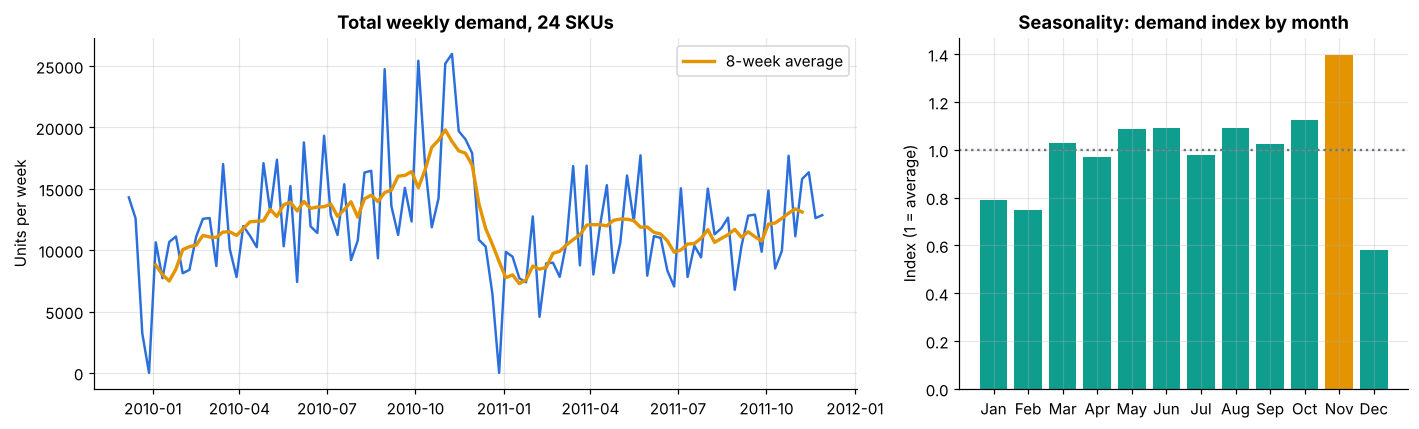

Monthly index: {1: 0.79, 2: 0.75, 3: 1.03, 4: 0.97, 5: 1.08, 6: 1.09, 7: 0.98, 8: 1.09, 9: 1.02, 10: 1.13, 11: 1.4, 12: 0.58}


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.7, 1]})
tot = panel.groupby("week")["demand"].sum()
axes[0].plot(tot.index, tot.values, color=BLUE, lw=1.6)
axes[0].plot(tot.index, tot.rolling(8, center=True).mean(), color=AMBER, lw=2.2, label="8-week average")
axes[0].set(title="Total weekly demand, 24 SKUs", ylabel="Units per week"); axes[0].legend()
p = panel.assign(month=panel["week"].dt.month)
idx = (p.groupby(["sku", "month"])["demand"].mean() / p.groupby("sku")["demand"].mean()).groupby("month").mean()
axes[1].bar(pd.to_datetime(idx.index, format="%m").strftime("%b"), idx.values,
            color=[AMBER if v > 1.2 else TEAL for v in idx.values])
axes[1].axhline(1, ls=":", color=GREY); axes[1].set(title="Seasonality: demand index by month", ylabel="Index (1 = average)")
plt.tight_layout(); plt.show()
print("Monthly index:", idx.round(2).to_dict())

**Interpretation.** Demand is strongly seasonal. November runs at 1.40× an average month and October at 1.13×, as shops stock up for Christmas. December falls to 0.58× because the business closes over the holidays. A forecasting model therefore needs a yearly-season signal; the Fourier terms and the same-week-last-year lag provide it.

## 5. Workstream 1: demand forecasting

**Method.**
- **Seven models:** naive; seasonal naive (same week last year); 4-week moving average; ETS with damped trend; ARIMA(1,0,1) with Fourier yearly terms and bank holidays (dynamic harmonic regression); and two ML regressions (ridge and gradient boosting).
- **The two ML regressions** are *global* models trained across all 24 SKUs at once. Their features are recent level, short trend, same week last year, price vs median price, the price-cut flag, UK bank holidays and Fourier seasonality. They forecast horizons 1–8 weeks directly.
- **Chronological split with rolling origins** (4-week horizon): validation origins cover 18 Jul 2011 – 03 Oct 2011 and test origins cover 10 Oct 2011 – 28 Nov 2011. A forecast made at an origin uses only data up to that week.
- **Automatic model selection:** the model with the lowest validation WAPE is chosen. It is scored once on the untouched test weeks.
- **Why no LSTM:** each SKU has only about 100 weekly observations, too few for a recurrent network to beat simpler models reliably. Pooling across SKUs in gradient boosting is the ML approach this much data supports.

In [17]:
t = time.time()
out = F.run_pipeline(panel, horizon=8, bt_horizon=4, strategy="global")
print(f"Pipeline run time: {time.time() - t:.0f} s")
sp = out["splits"]
print(f"Training up to {sp['train_end']:%d %b %Y} | validation {sp['val_weeks'][0]:%d %b %Y} – {sp['val_weeks'][1]:%d %b %Y} | "
      f"test {sp['test_weeks'][0]:%d %b %Y} – {sp['test_weeks'][1]:%d %b %Y}")
comp = out["val_metrics"].set_index("model")[["MAE", "RMSE", "WAPE"]].add_prefix("val_").join(
       out["test_metrics"].set_index("model")[["MAE", "RMSE", "WAPE", "MAPE", "Bias"]].add_prefix("test_"), how="outer")
comp.sort_values("val_WAPE").round(3)

Pipeline run time: 27 s
Training up to 11 Jul 2011 | validation 18 Jul 2011 – 03 Oct 2011 | test 10 Oct 2011 – 28 Nov 2011


,val_MAE,val_RMSE,val_WAPE,test_MAE,test_RMSE,test_WAPE,test_MAPE,test_Bias
model,,,,,,,,
Ridge regression,215.277,342.579,0.449,291.030,541.812,0.533,1.027,0.027
Gradient boosting,219.264,343.510,0.457,264.937,530.127,0.485,0.794,-0.016
Moving average (4w),247.953,413.006,0.517,296.760,547.611,0.543,0.910,-0.068
ETS (damped trend),255.744,411.397,0.533,286.953,554.208,0.525,0.962,-0.091
ARIMA + Fourier,305.380,451.611,0.637,389.764,582.576,0.713,1.509,0.350
Naive,310.722,487.271,0.648,381.260,682.966,0.698,1.148,-0.009
Seasonal naive,421.431,925.924,0.879,478.047,931.291,0.875,1.704,0.438
AI-selected (global),NaN,NaN,NaN,291.030,541.812,0.533,1.027,0.027
AI-selected (per SKU),NaN,NaN,NaN,310.476,573.299,0.568,0.970,0.038


Selected model (lowest validation WAPE): Ridge regression
Test WAPE of the selected model: 53.3% | naive: 69.8% | seasonal naive: 87.5%
Best test WAPE of any model: Gradient boosting (48.5%); per-SKU selection: 56.8%


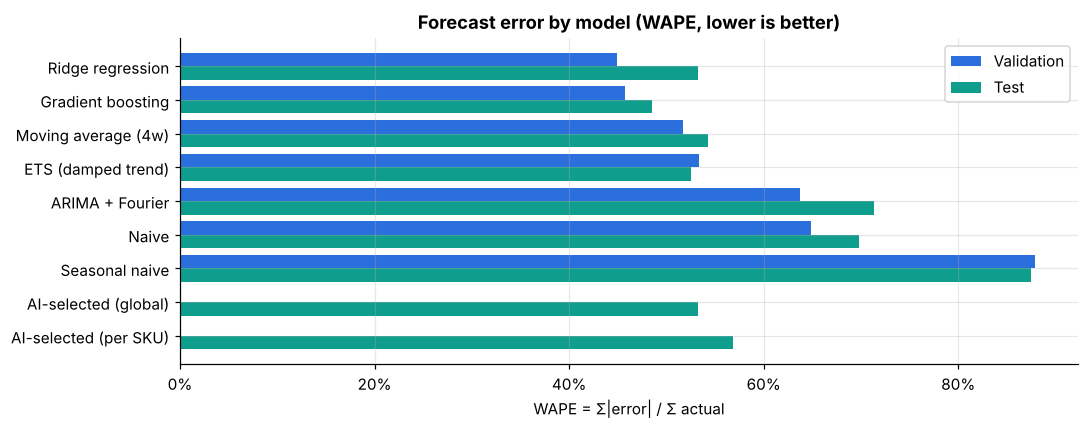

In [18]:
best_model = out["best"]["best_model"].iat[0]
tm = out["test_metrics"].set_index("model")
print("Selected model (lowest validation WAPE):", best_model)
print(f"Test WAPE of the selected model: {tm.loc['AI-selected (global)', 'WAPE']:.1%} | naive: {tm.loc['Naive', 'WAPE']:.1%} | "
      f"seasonal naive: {tm.loc['Seasonal naive', 'WAPE']:.1%}")
print(f"Best test WAPE of any model: {tm['WAPE'].idxmin()} ({tm['WAPE'].min():.1%}); per-SKU selection: {tm.loc['AI-selected (per SKU)', 'WAPE']:.1%}")
d = comp.sort_values("val_WAPE")
fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(d))
ax.barh(y - 0.2, d["val_WAPE"], 0.4, color=BLUE, label="Validation")
ax.barh(y + 0.2, d["test_WAPE"], 0.4, color=TEAL, label="Test")
ax.set_yticks(y, d.index); ax.invert_yaxis(); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(title="Forecast error by model (WAPE, lower is better)", xlabel="WAPE = Σ|error| / Σ actual"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretation.** On the validation weeks, **Ridge regression** has the lowest WAPE (44.9%), so it is selected automatically. On the unseen test weeks it scores 53.3%, against 69.8% for the naive forecast and 87.5% for the seasonal naive. Errors remain large in absolute terms because B2B gift orders are lumpy: one wholesale order can be several weeks' typical demand.

Two honest observations:
1. On the test weeks the best single model is Gradient boosting (48.5%). Rankings shift between windows, so the selection uses only validation data and is reported without hindsight.
2. Picking a different model for each SKU does worse on test (56.8%). With 12 validation weeks per SKU, per-SKU choices mostly fit noise, so one global choice is more robust.

MAPE is shown for reference only: it is undefined in weeks with zero demand and over-weights small weeks.

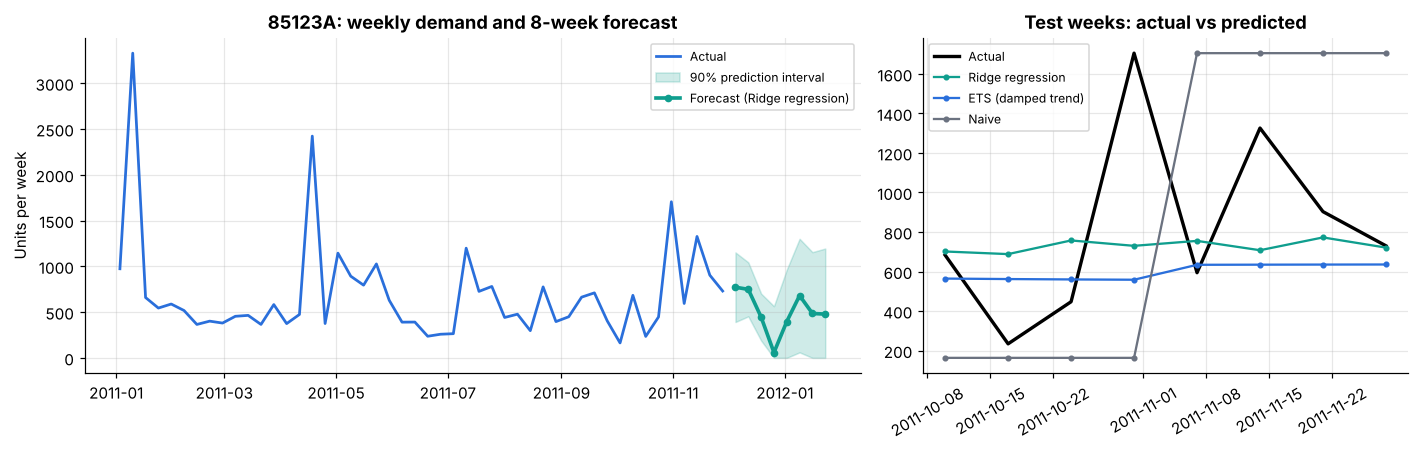

      week  forecast    lo     hi
2011-12-05     771.0 392.0 1151.0
2011-12-12     748.0 453.0 1043.0
2011-12-19     445.0 189.0  701.0
2011-12-26      58.0   0.0  564.0
2012-01-02     397.0   0.0  963.0
2012-01-09     680.0  60.0 1300.0
2012-01-16     485.0   0.0 1154.0
2012-01-23     478.0   0.0 1194.0


In [19]:
EX = "85123A"                      # White Hanging Heart T-Light Holder: the best-known product in the dataset
hist = panel[panel["sku"] == EX].set_index("week")["demand"]
fc = out["forecast"][out["forecast"]["sku"] == EX]
tb = out["test_bt"][(out["test_bt"]["sku"] == EX)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
h = hist[hist.index >= "2011-01-01"]
axes[0].plot(h.index, h.values, color=BLUE, lw=1.8, label="Actual")
axes[0].fill_between(fc["week"], fc["lo"], fc["hi"], color=TEAL, alpha=0.2, label="90% prediction interval")
axes[0].plot(fc["week"], fc["forecast"], color=TEAL, lw=2.4, marker="o", ms=4, label=f"Forecast ({best_model})")
axes[0].set(title=f"{EX}: weekly demand and 8-week forecast", ylabel="Units per week"); axes[0].legend(fontsize=8)
act = tb.drop_duplicates("week").sort_values("week")
axes[1].plot(act["week"], act["actual"], color="black", lw=2.2, label="Actual")
for m, c in [(best_model, TEAL), ("ETS (damped trend)", BLUE), ("Naive", GREY)]:
    dm = tb[tb["model"] == m].sort_values("week")
    axes[1].plot(dm["week"], dm["forecast"], marker="o", ms=3, color=c, label=m)
axes[1].set(title="Test weeks: actual vs predicted"); axes[1].tick_params(axis="x", rotation=30); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(fc[["week", "forecast", "lo", "hi"]].round(0).to_string(index=False))

**Prediction intervals.** The 90 % band for each horizon comes from the selected model's own validation errors at that horizon: ±1.645 × RMSE(h). It is therefore an honest measure of how wrong the model has actually been, not a theoretical figure.

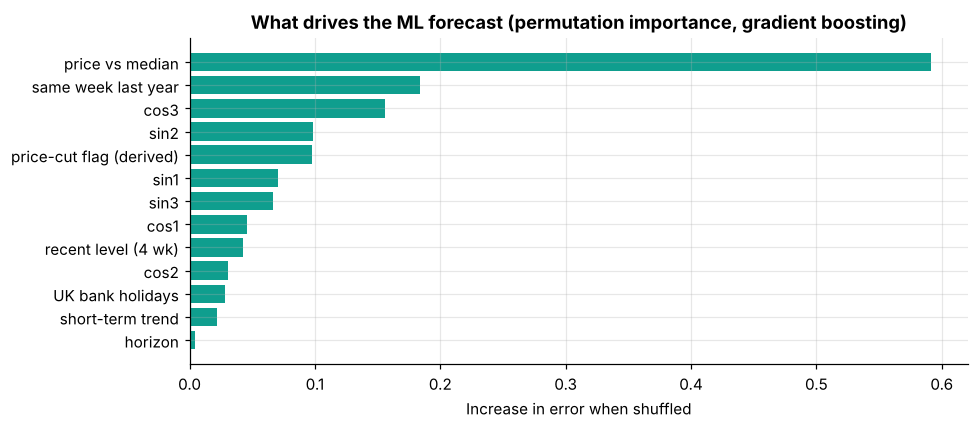

price_ratio    0.5914
lag52_ratio    0.1837
cos3           0.1562
sin2           0.0988
price_cut      0.0980
sin1           0.0704
sin3           0.0668
cos1           0.0454
lvl4_ratio     0.0429
cos2           0.0309
hol            0.0286
trend          0.0222
h              0.0047


In [20]:
from sklearn.inspection import permutation_importance
W = F.wide_demand(panel)
P = panel.pivot(index="week", columns="sku", values="avg_price"); C = panel.pivot(index="week", columns="sku", values="price_cut")
train = F._ml_train_set(panel, len(W) - 1, W.index, W, P, C)
gbm = F._fit_ml("Gradient boosting", train)
smp = train.sample(3000, random_state=SEED)
pi = permutation_importance(gbm, smp[F.ML_FEATURES], smp["y_ratio"], n_repeats=5, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=F.ML_FEATURES).sort_values()
names = {"lvl4_ratio": "recent level (4 wk)", "trend": "short-term trend", "lag52_ratio": "same week last year",
         "price_ratio": "price vs median", "price_cut": "price-cut flag (derived)", "hol": "UK bank holidays", "h": "horizon"}
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh([names.get(i, i) for i in imp.index], imp.values, color=[TEAL if v > 0 else GREY for v in imp.values])
ax.set(title="What drives the ML forecast (permutation importance, gradient boosting)", xlabel="Increase in error when shuffled")
plt.tight_layout(); plt.show()
print(imp.sort_values(ascending=False).round(4).to_string())

**Interpretation.** The strongest driver is **price vs median**. Seasonality enters through the Fourier terms and the same-week-last-year lag, price through the price ratio, and external factors through the bank-holiday count. So the model uses every factor the slide lists that the data can supply. Promotions are not recorded in this dataset, so the derived price-cut flag stands in as a proxy, and it should be read with care: it may also capture bulk-price tiers.

## 6. Adding new data and updating forecasts continuously

The slide asks to *"keep the possibility of adding new data"* and to *"continuously update forecasts as new data arrives"*. This is shown in two ways:
1. **New-data intake.** A batch of raw transactions goes through `validate_new_data` (schema mapping, date and number checks, duplicate removal) and is merged with `append_weekly`, which appends new weeks and reconciles overlapping ones. The dashboard's *Data management* page does the same with uploaded CSVs and a replay feed.
2. **Updating vs static model.** Starting from data up to 03 Oct 2011, the 8 later weeks arrive one at a time. An *updating* model is refitted after every arrival and forecasts the next week. A *static* model is fitted once at the cut-off and is never refreshed.

In [21]:
CUT = pd.Timestamp("2011-10-03")
base = panel[panel["week"] <= CUT]
late = clean[clean["InvoiceDate"] >= CUT + pd.Timedelta(days=7)]
first_week = late[late["InvoiceDate"] < CUT + pd.Timedelta(days=14)].rename(columns={"StockCode": "sku"})
v = D.validate_new_data(first_week, D.detect_columns(first_week))
print("Validation OK:", v.ok, "| warnings:", v.warnings or "none", "| weekly rows produced:", len(v.data))
updated, info = D.append_weekly(base, v.data)
print("Append result:", info)
print(f"Panel grew from {base['week'].nunique()} to {updated['week'].nunique()} weeks; last week now {updated['week'].max():%d %b %Y}")

Validation OK: True | warnings: ['6 exact duplicate row(s) were removed.'] | weekly rows produced: 2129
Append result: {'rows_in': 2129, 'rows_used': 24, 'unknown_skus': ['10080', '10135', '11001', '15034', '15039', '15044D', '15056N', '15056P', '15060B', '16008'], 'replaced': 0, 'new_weeks': 1}
Panel grew from 96 to 97 weeks; last week now 10 Oct 2011


                       MAE     RMSE   WAPE
mode                                      
Static (fit once)  305.415  557.290  0.559
Updated weekly     276.951  518.088  0.507


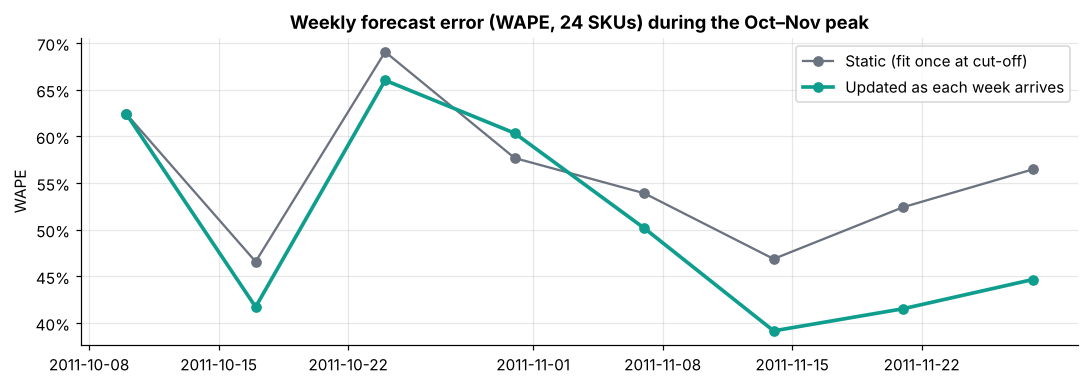

In [22]:
weeks = pd.DatetimeIndex(sorted(panel["week"].unique()))
cut_i = int(np.where(weeks == CUT)[0][0])
upd_origins = list(range(cut_i, len(weeks) - 1))                       # refit after every new week, forecast 1 week ahead
upd = F.backtest(panel, upd_origins, horizon=1, models=[best_model]).assign(mode="Updated weekly")
static = F.backtest(panel, [cut_i], horizon=len(weeks) - 1 - cut_i, models=[best_model]).assign(mode="Static (fit once)")
both = pd.concat([upd, static])
cmp_ = F.metrics(both, by=("mode",)).set_index("mode")[["MAE", "RMSE", "WAPE"]]
print(cmp_.round(3).to_string())
wk = both.groupby(["mode", "week"]).apply(lambda g: (g["forecast"] - g["actual"]).abs().sum() / g["actual"].sum(), include_groups=False).unstack(0)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(wk.index, wk["Static (fit once)"], marker="o", color=GREY, label="Static (fit once at cut-off)")
ax.plot(wk.index, wk["Updated weekly"], marker="o", color=TEAL, lw=2.4, label="Updated as each week arrives")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(title="Weekly forecast error (WAPE, 24 SKUs) during the Oct–Nov peak", ylabel="WAPE"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretation.** Through the October–November peak, refreshing the model with each new week cuts the pooled WAPE from 55.9% (static) to **50.7%** (updated). That is 9% less error, and it is the practical meaning of "continuously update forecasts as new data arrives". The refresh is an on-demand batch step, not a real-time stream; the dashboard labels it the same way.

## 7. Workstream 2a: dynamic safety stock and reorder point (probabilistic model)

**Method.** For each SKU:
- **D̄** = mean of the AI forecast over the next 8 weeks (forward-looking, so it moves with the season).
- **σ_D** = RMSE of the selected model's forecast errors on validation. This is the uncertainty that remains *after* forecasting, the right input for a forecast-driven buffer. The historical SD is shown for comparison.
- **Z** from the 95 % cycle service level; L = 3 weeks and σ_L = 1 week (**assumptions**).

Then $SS = Z\sqrt{\sigma_D^2 L + \bar D^2 \sigma_L^2}$ and $ROP = \bar D L + SS$.

In [23]:
LEAD, LEAD_SD, SL = 3.0, 1.0, 0.95
COST_RATIO, HOLD, ORDER_COST, SHORT_MULT = 0.60, 0.25, 60.0, 1.0
fcm = out["forecast"].groupby("sku")["forecast"].mean().rename("d_bar")
vb = out["val_bt"][out["val_bt"]["model"] == best_model]
rmse = vb.assign(e=vb["forecast"] - vb["actual"]).groupby("sku")["e"].apply(lambda e: np.sqrt((e ** 2).mean())).rename("sigma_d")
last26 = panel[panel["week"] > panel["week"].max() - pd.Timedelta(weeks=26)].groupby("sku")["demand"].std().rename("hist_sd")
price = panel.groupby("sku")["avg_price"].median().rename("price")
desc = panel.groupby("sku")["description"].first()
params = pd.concat([desc, fcm, rmse, last26, price], axis=1).reset_index().rename(columns={"index": "sku"})
params["unit_cost"] = params["price"] * COST_RATIO
z = I.z_value(SL)
params["SS_forecast_err"] = [I.safety_stock(z, s, LEAD, d, LEAD_SD) for d, s in zip(params["d_bar"], params["sigma_d"])]
params["SS_hist_sd"] = [I.safety_stock(z, s, LEAD, d, LEAD_SD) for d, s in zip(params["d_bar"], params["hist_sd"])]
params["ROP"] = params["d_bar"] * LEAD + params["SS_forecast_err"]
print(f"Z for {SL:.0%} = {z:.4f}")
print(f"Median σ_D: forecast-error {params['sigma_d'].median():,.0f} vs historical SD {params['hist_sd'].median():,.0f} units/week")
params[["sku", "description", "d_bar", "sigma_d", "hist_sd", "SS_forecast_err", "SS_hist_sd", "ROP"]].round(0).sort_values("ROP", ascending=False)

Z for 95% = 1.6449
Median σ_D: forecast-error 216 vs historical SD 267 units/week


,sku,description,d_bar,sigma_d,hist_sd,SS_forecast_err,SS_hist_sd,ROP
11,22197,Small Popcorn Holder,1296.0,520.0,1079.0,2597.0,3741.0,6485.0
17,84879,Assorted Colour Bird Ornament,604.0,890.0,711.0,2724.0,2256.0,4536.0
21,85099B,Jumbo Bag Red Retrospot,714.0,616.0,521.0,2113.0,1894.0,4256.0
15,84077,World War 2 Gliders Asstd Designs,534.0,394.0,955.0,1425.0,2860.0,3027.0
6,21213,Pack Of 72 Skull Cake Cases,544.0,198.0,230.0,1058.0,1109.0,2690.0
23,85123A,White Hanging Heart T-Light Holder,508.0,226.0,366.0,1055.0,1336.0,2578.0
13,22386,Jumbo Bag Pink Polkadot,318.0,360.0,277.0,1151.0,947.0,2105.0
18,84946,Antique Silver Tea Glass Etched,335.0,205.0,241.0,804.0,881.0,1810.0
9,21977,Pack Of 60 Pink Paisley Cake Cases,203.0,352.0,314.0,1056.0,955.0,1665.0
10,22178,Victorian Glass Hanging T-Light,187.0,350.0,324.0,1045.0,973.0,1605.0


In [24]:
r = params.set_index("sku").loc[EX]
dv, lv = r.sigma_d ** 2 * LEAD, r.d_bar ** 2 * LEAD_SD ** 2
print(f"Hand check for {EX} ({r.description}):")
print(f"  SS = {z:.3f} × sqrt({r.sigma_d:,.1f}² × {LEAD:g} + {r.d_bar:,.1f}² × {LEAD_SD:g}²) = {z:.3f} × {np.sqrt(dv + lv):,.1f} = {r.SS_forecast_err:,.1f}")
print(f"  ROP = {r.d_bar:,.1f} × {LEAD:g} + {r.SS_forecast_err:,.1f} = {r.ROP:,.1f}")
print(f"  Share of lead-time variance from demand: {dv / (dv + lv):.0%}, from lead time: {lv / (dv + lv):.0%}")

Hand check for 85123A (White Hanging Heart T-Light Holder):
  SS = 1.645 × sqrt(226.1² × 3 + 507.8² × 1²) = 1.645 × 641.3 = 1,054.8
  ROP = 507.8 × 3 + 1,054.8 = 2,578.2
  Share of lead-time variance from demand: 37%, from lead time: 63%


**Interpretation.** For 85123A (White Hanging Heart T-Light Holder), the formula gives a safety stock of **1,055 units** and a reorder point of **2,578 units**. Of the lead-time variance, 37% comes from demand and 63% from the supplier's lead time. Using forecast error instead of raw historical variability changes the buffer: the median σ_D is 216 vs 267 units/week. Because demand is forecast forward, the buffer is *dynamic*: it rises into the peak season and falls after it.

## 8. Workstream 2b: Monte Carlo simulation of risk scenarios and buffers

**Why simulate?** The formula assumes that weekly demands are independent and normal, and that lead time is independent of demand. Real gift demand is right-skewed, and supplier delays often coincide with peak demand. The simulation drops these assumptions:
- Each run draws a lead time (gamma, mean 3, SD 1 week) and the weekly demands during it (gamma, matching D̄ and σ_D).
- It sums the lead-time demand (DLT), and repeats this 10,000 times with seed 42.
- The buffer is the 95th percentile of DLT minus its expected value.
- A Gaussian copula sets the demand–lead-time correlation ρ; ρ = 0 reproduces the formula's independence.

85123A: formula SS 1,055 | Monte Carlo SS 1,172 | MC ROP 2,695
Simulated cycle service level if the formula ROP is used: 93.6% (target 95%)
Expected shortage per cycle at formula ROP: 28.2 units | P99 lead-time demand: 3,415


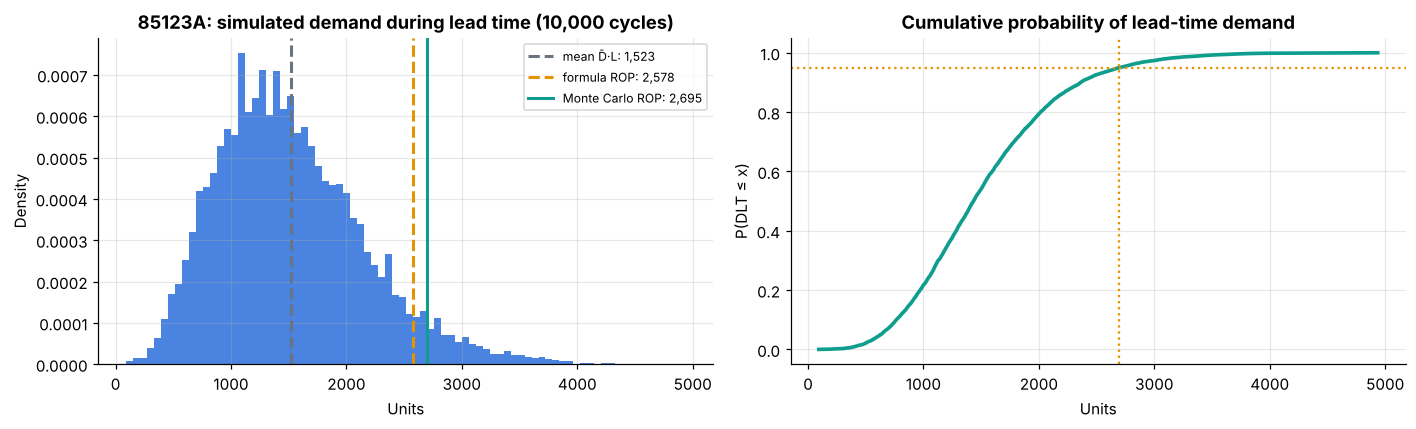

In [25]:
r = params.set_index("sku").loc[EX]
sim = S.lead_time_demand(10_000, r.d_bar, r.sigma_d, LEAD, LEAD_SD, "Gamma", "Gamma", rho=0.0, seed=SEED)
mc = S.summarise_dlt(sim["dlt"], SL, rop=r.ROP, q=1000, d_mean=r.d_bar, l_mean=LEAD)
print(f"{EX}: formula SS {r.SS_forecast_err:,.0f} | Monte Carlo SS {mc['ss_mc']:,.0f} | MC ROP {mc['rop_mc']:,.0f}")
print(f"Simulated cycle service level if the formula ROP is used: {mc['cycle_service_level']:.1%} (target {SL:.0%})")
print(f"Expected shortage per cycle at formula ROP: {mc['expected_shortage']:,.1f} units | P99 lead-time demand: {mc['p99']:,.0f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(sim["dlt"], bins=80, color=BLUE, alpha=0.85, density=True)
for x, lab, c in [(r.d_bar * LEAD, "mean D̄·L", GREY), (r.ROP, "formula ROP", AMBER), (mc["rop_mc"], "Monte Carlo ROP", TEAL)]:
    axes[0].axvline(x, color=c, lw=2, ls="--" if c != TEAL else "-", label=f"{lab}: {x:,.0f}")
axes[0].set(title=f"{EX}: simulated demand during lead time (10,000 cycles)", xlabel="Units", ylabel="Density"); axes[0].legend(fontsize=8)
xs = np.sort(sim["dlt"]); axes[1].plot(xs, np.arange(1, len(xs) + 1) / len(xs), color=TEAL, lw=2.4)
axes[1].axhline(SL, color=AMBER, ls=":"); axes[1].axvline(mc["rop_mc"], color=AMBER, ls=":")
axes[1].set(title="Cumulative probability of lead-time demand", xlabel="Units", ylabel="P(DLT ≤ x)")
plt.tight_layout(); plt.show()

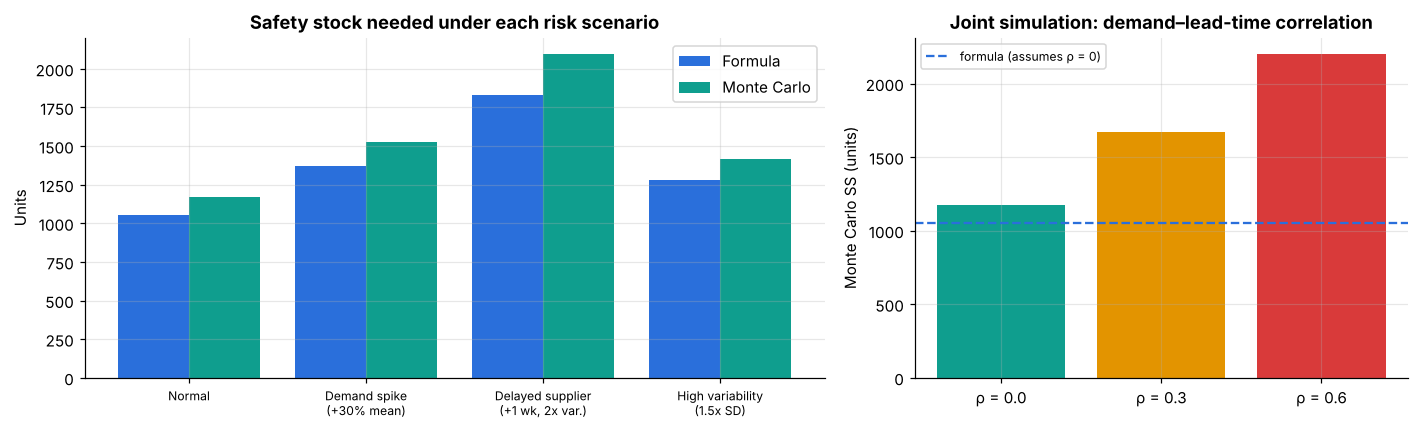

                         scenario  mean demand/wk  demand SD/wk  lead time (wk)  lead-time SD (wk)  SS formula  SS Monte Carlo  ROP Monte Carlo  P(stockout) at current ROP  Exp. shortage/cycle at current ROP
                           Normal         507.820       226.070             3.0                1.0    1054.765        1171.850         2695.309                       0.064                              28.197
         Demand spike (+30% mean)         660.166       293.891             3.0                1.0    1371.195        1523.405         3503.902                       0.213                             132.915
Delayed supplier (+1 wk, 2x var.)         507.820       226.070             4.0                2.0    1828.641        2095.304         4126.583                       0.259                             244.722
       High variability (1.5x SD)         507.820       339.105             3.0                1.0    1277.129        1413.033         2936.492                       0.

In [26]:
scen = S.scenario_table(10_000, r.d_bar, r.sigma_d, LEAD, LEAD_SD, SL, r.ROP, "Gamma", "Gamma", 0.0, seed=SEED)
rhos = [0.0, 0.3, 0.6]
rho_ss = [S.summarise_dlt(S.lead_time_demand(10_000, r.d_bar, r.sigma_d, LEAD, LEAD_SD, rho=k, seed=SEED)["dlt"], SL,
                          d_mean=r.d_bar, l_mean=LEAD)["ss_mc"] for k in rhos]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.5, 1]})
x = np.arange(len(scen))
axes[0].bar(x - 0.2, scen["SS formula"], 0.4, color=BLUE, label="Formula")
axes[0].bar(x + 0.2, scen["SS Monte Carlo"], 0.4, color=TEAL, label="Monte Carlo")
axes[0].set_xticks(x, [s.replace(" (", "\n(") for s in scen["scenario"]], fontsize=8)
axes[0].set(title="Safety stock needed under each risk scenario", ylabel="Units"); axes[0].legend()
axes[1].bar([f"ρ = {k}" for k in rhos], rho_ss, color=[TEAL, AMBER, RED])
axes[1].axhline(r.SS_forecast_err, color=BLUE, ls="--", label="formula (assumes ρ = 0)")
axes[1].set(title="Joint simulation: demand–lead-time correlation", ylabel="Monte Carlo SS (units)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(scen.round(3).to_string(index=False))
print("SS by correlation:", dict(zip(rhos, np.round(rho_ss, 0))))

In [27]:
rows = []
for rr in params.itertuples():
    s_ = S.lead_time_demand(10_000, rr.d_bar, rr.sigma_d, LEAD, LEAD_SD, seed=SEED)
    m_ = S.summarise_dlt(s_["dlt"], SL, rop=rr.ROP, d_mean=rr.d_bar, l_mean=LEAD)
    rows.append({"sku": rr.sku, "SS formula": rr.SS_forecast_err, "SS Monte Carlo": m_["ss_mc"], "CSL of formula ROP": m_["cycle_service_level"]})
allmc = pd.DataFrame(rows)
allmc["diff %"] = allmc["SS Monte Carlo"] / allmc["SS formula"] - 1
print(f"SKUs where the simulation needs more buffer than the formula: {(allmc['diff %'] > 0).sum()} of {len(allmc)}")
print(f"Median extra buffer: {allmc['diff %'].median():+.1%} | median simulated CSL of the formula ROP: {allmc['CSL of formula ROP'].median():.1%}")
allmc.round(3).sort_values("diff %", ascending=False).head(8)

SKUs where the simulation needs more buffer than the formula: 23 of 24
Median extra buffer: +13.2% | median simulated CSL of the formula ROP: 93.5%


,sku,SS formula,SS Monte Carlo,CSL of formula ROP,diff %
16,84755,564.773,678.968,0.934,0.202
10,22178,1044.620,1240.646,0.931,0.188
9,21977,1055.976,1253.334,0.930,0.187
8,21975,597.602,708.915,0.930,0.186
22,85099F,882.539,1041.084,0.929,0.180
17,84879,2723.810,3191.337,0.928,0.172
2,20724,515.298,601.207,0.929,0.167
5,21212,914.474,1066.033,0.928,0.166


**Interpretation.**
- **Skewed demand.** For 85123A, the simulation needs **1,172** units of buffer against **1,055** from the formula. If the formula ROP is kept, the true cycle service level is only **93.6%**, not 95 %. Across all SKUs, 23 of 24 need more buffer than the formula suggests (median +13.2%).
- **Risk scenarios.** Keeping today's ROP, a supplier delay (+1 week, double variability) raises the stockout probability to 26% per cycle, and a +30 % demand spike raises it to 21%.
- **Dependence.** If supplier delays coincide with high demand (ρ = 0.6), the needed buffer rises to 2,200 units. Here the independence assumption behind the formula is clearly broken, and only the joint simulation gives the right answer.
- **Service measures.** These figures are *cycle service levels* (no stockout in a replenishment cycle). They are not fill rates, which measure the share of units served.

## 9. Workstream 3: AI-driven sensitivity analysis with Bayesian optimisation

Instead of sweeping ROP and Q by hand, **Bayesian optimisation** (Optuna's TPE sampler, a sequential model-based optimiser) searches both at once.

**Decision variables:** reorder point *s* and order quantity *Q* under an (s, nQ) policy with backorders. The safety stock follows as s − D̄L.

**Objective:** minimise expected annual cost = holding (unit cost × 25 %/yr × average stock) + ordering (£60 × orders) + shortage (selling price × units short).

**Constraints** (Optuna treats a trial as feasible when every constraint is ≤ 0):
- cycle service level ≥ 95 %
- 99th-percentile peak stock ≤ warehouse capacity
- average stock value ≤ budget
- MOQ ≤ Q ≤ maximum supplier order

**Fair comparison:** every trial is scored on the same 200 simulated years of demand and lead times (common random numbers, seed 42). The winner and the baseline (formula ROP + EOQ) are then re-scored on 400 fresh years (seed 1042).

In [28]:
r = params.set_index("sku").loc[EX]
sc = O.Scenario(d_mean=r.d_bar, d_sd=r.sigma_d, l_mean=LEAD, l_sd=LEAD_SD, unit_cost=r.unit_cost, holding_rate=HOLD,
                order_cost=ORDER_COST, shortage_cost=r.price * SHORT_MULT, target_csl=SL,
                capacity=round(r.ROP + 4 * r.d_bar * 4, -2), budget=round(r.unit_cost * r.d_bar * 9, -1),
                moq=500, q_max=round(26 * r.d_bar, -2), n_paths=200, seed=SEED)
t = time.time(); res = O.optimise(sc, n_trials=100, sampler="TPE"); bo_time = time.time() - t
b, bv, base, bval = res["best"], res["best_validation"], res["baseline"], res["baseline_validation"]
print(f"Constraints: CSL ≥ {sc.target_csl:.0%}, capacity {sc.capacity:,.0f} units, budget £{sc.budget:,.0f}, MOQ {sc.moq:,.0f}, max order {sc.q_max:,.0f}")
print(f"100 trials in {bo_time:.1f} s; feasible trials: {res['history']['feasible'].sum()}")
tbl = pd.DataFrame({"Baseline (formula ROP + EOQ)": bval, "Bayesian-optimised": bv}).loc[
    ["rop", "q", "ss", "holding_cost", "ordering_cost", "shortage_cost", "total_cost", "cycle_service_level", "fill_rate",
     "p99_max_on_hand", "avg_on_hand", "feasible"]]
print("\nValidation on 400 fresh simulated years:"); print(tbl.to_string())
saving = 1 - bv["total_cost"] / bval["total_cost"]
print(f"\nCost change vs baseline: {-saving:+.1%}")

Constraints: CSL ≥ 95%, capacity 10,700 units, budget £7,580, MOQ 500, max order 13,200
100 trials in 0.3 s; feasible trials: 56

Validation on 400 fresh simulated years:
                    Baseline (formula ROP + EOQ) Bayesian-optimised
rop                                  2578.224617        2956.892045
q                                    2765.424113        3605.489645
ss                                   1054.765329        1433.432757
holding_cost                         1009.637721        1339.021944
ordering_cost                              571.2             433.95
shortage_cost                         494.591545         161.321612
total_cost                           2075.429266        1934.293556
cycle_service_level                     0.953653           0.982585
fill_rate                               0.993231           0.997792
p99_max_on_hand                      5318.666709         6550.30186
avg_on_hand                          2436.659644        3231.595518
feasible     

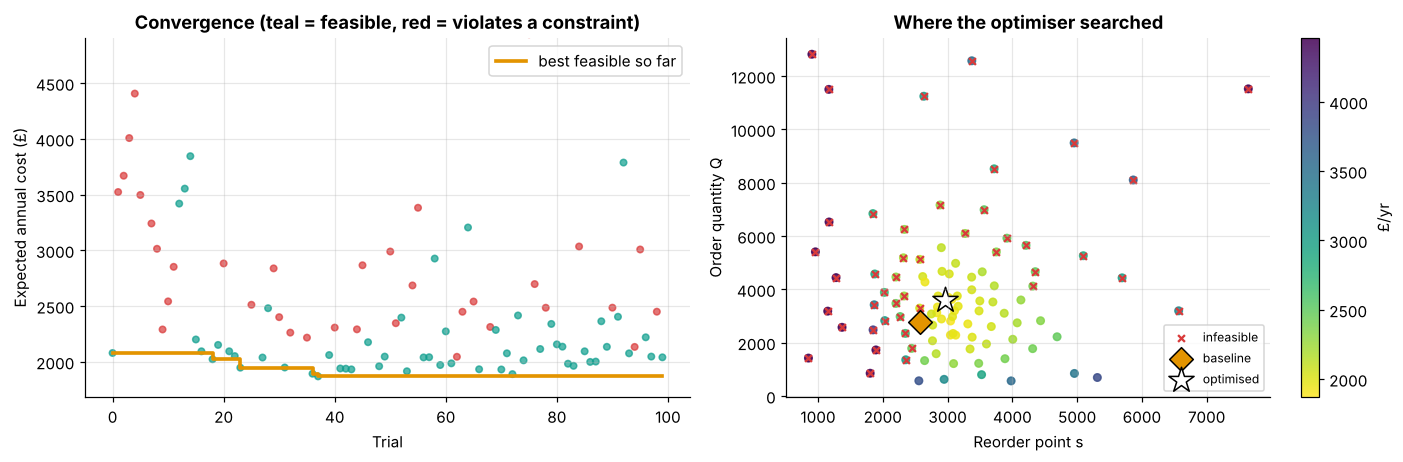

In [29]:
h = res["history"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].scatter(h["trial"], h["cost"], c=np.where(h["feasible"], TEAL, RED), s=18, alpha=0.7)
axes[0].step(h["trial"], h["best_feasible_so_far"], where="post", color=AMBER, lw=2.4, label="best feasible so far")
axes[0].set_ylim(h["cost"].min() * 0.9, np.nanpercentile(h["cost"], 90) * 1.1)
axes[0].set(title="Convergence (teal = feasible, red = violates a constraint)", xlabel="Trial", ylabel="Expected annual cost (£)"); axes[0].legend()
sca = axes[1].scatter(h["rop"], h["q"], c=h["cost"].clip(upper=np.nanpercentile(h["cost"], 90)), cmap="viridis_r", s=24,
                      marker="o", alpha=0.85)
axes[1].scatter(h.loc[~h["feasible"], "rop"], h.loc[~h["feasible"], "q"], marker="x", color=RED, s=20, label="infeasible")
axes[1].scatter([base["rop"]], [base["q"]], marker="D", s=120, color=AMBER, edgecolor="black", label="baseline")
axes[1].scatter([b["rop"]], [b["q"]], marker="*", s=300, color="white", edgecolor="black", label="optimised")
plt.colorbar(sca, ax=axes[1], label="£/yr")
axes[1].set(title="Where the optimiser searched", xlabel="Reorder point s", ylabel="Order quantity Q"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.**
- **Baseline.** For 85123A, the formula ROP (2,578) with Q = EOQ (2,765) reaches 95.4% cycle service on fresh simulated demand (meets the 95 % target). Its expected cost is £2,075/yr, of which £495 is shortage cost.
- **Optimised.** The optimiser finds ROP **2,957** and Q **3,605**. That policy meets every constraint (98.3% CSL, within capacity and budget) at £1,934/yr, a -6.8% change. It deliberately holds more stock: holding cost rises from £1,010 to £1,339. In return, shortage cost falls from £495 to £161, and fewer, larger orders cut ordering cost from £571 to £434. That trade-off is exactly what a manual one-parameter sweep misses.
- **Search.** The convergence chart shows the search settling within a few dozen trials. The scatter shows it concentrating around the low-cost, feasible region rather than sweeping a grid.

In [30]:
summary_rows = []
t = time.time()
for rr in params.itertuples():
    sc_ = O.Scenario(d_mean=rr.d_bar, d_sd=rr.sigma_d, l_mean=LEAD, l_sd=LEAD_SD, unit_cost=rr.unit_cost, holding_rate=HOLD,
                     order_cost=ORDER_COST, shortage_cost=rr.price * SHORT_MULT, target_csl=SL, n_paths=120, seed=SEED)
    rs = O.optimise(sc_, n_trials=60)
    summary_rows.append({"sku": rr.sku, "baseline_cost": rs["baseline_validation"]["total_cost"],
                         "baseline_csl": rs["baseline_validation"]["cycle_service_level"],
                         "opt_cost": rs["best_validation"]["total_cost"], "opt_csl": rs["best_validation"]["cycle_service_level"],
                         "opt_rop": rs["best"]["rop"], "formula_rop": rs["baseline"]["rop"]})
allbo = pd.DataFrame(summary_rows)
print(f"Optimised 24 SKUs in {time.time() - t:.0f} s")
print(f"Baseline policies meeting the 95% CSL target on validation: {(allbo['baseline_csl'] >= SL).sum()} of 24")
print(f"Optimised policies meeting it: {(allbo['opt_csl'] >= SL).sum()} of 24")
print(f"Total expected cost: baseline £{allbo['baseline_cost'].sum():,.0f}/yr → optimised £{allbo['opt_cost'].sum():,.0f}/yr "
      f"({allbo['opt_cost'].sum() / allbo['baseline_cost'].sum() - 1:+.1%})")
print(f"Median optimised ROP vs formula ROP: {(allbo['opt_rop'] / allbo['formula_rop'] - 1).median():+.1%}")

Optimised 24 SKUs in 4 s
Baseline policies meeting the 95% CSL target on validation: 6 of 24
Optimised policies meeting it: 20 of 24
Total expected cost: baseline £22,154/yr → optimised £20,800/yr (-6.1%)
Median optimised ROP vs formula ROP: +16.3%


**Interpretation across the range.** Run for all 24 SKUs (60 trials each, no capacity or budget limit), the textbook baseline meets the 95 % service target on fresh simulations for only 6 of 24 SKUs. The Bayesian-optimised policies meet it for 20 of 24, and total expected cost changes from £22,154 to £20,800 per year (-6.1%). In this case the AI-driven sensitivity analysis does more than tune: it closes most of a hidden service gap and lowers cost at the same time. The 4 SKU(s) still slightly short on fresh paths would need more trials, or a small safety margin on the service constraint, because the optimiser sees only 120 simulated years per trial.

## 10. Inventory intelligence: what to order this week (scenario)
Stock on hand is **not** in the dataset, so this section uses a clearly labelled **simulated** starting position: 2–10 weeks of forecast cover, with the same seed as the dashboard. The status rules are: Critical if position ≤ SS; Reorder Now if position ≤ ROP; Monitor if position ≤ ROP + 2 weeks of demand; otherwise Healthy.

In [31]:
rng = np.random.default_rng(7)
stock = pd.DataFrame({"sku": params["sku"], "on_hand": np.round(params["d_bar"].values * rng.uniform(2.0, 10.0, len(params))),
                      "on_order": 0.0, "backorders": 0.0})
pt = I.sku_policy_table(params.drop(columns=["ROP"]).merge(stock, on="sku"), SL, LEAD, LEAD_SD, ORDER_COST, HOLD)
print("SIMULATED stock scenario. Status counts:", pt["status"].value_counts().to_dict())
pt[["sku", "description", "on_hand", "safety_stock", "rop", "status", "order_qty", "action"]].round(0).sort_values("rop", ascending=False).head(12)

SIMULATED stock scenario. Status counts: {'Reorder Now': 13, 'Monitor': 6, 'Critical Stockout Risk': 3, 'Healthy': 2}


,sku,description,on_hand,safety_stock,rop,status,order_qty,action
11,22197,Small Popcorn Holder,5480.0,2597.0,6485.0,Reorder Now,8080.0,Place a replenishment order this week
17,84879,Assorted Colour Bird Ornament,5039.0,2724.0,4536.0,Monitor,0.0,No order yet; review again next week
21,85099B,Jumbo Bag Red Retrospot,2344.0,2113.0,4256.0,Reorder Now,3968.0,Place a replenishment order this week
15,84077,World War 2 Gliders Asstd Designs,3433.0,1425.0,3027.0,Monitor,0.0,No order yet; review again next week
6,21213,Pack Of 72 Skull Cake Cases,1111.0,1058.0,2690.0,Reorder Now,6415.0,Place a replenishment order this week
23,85123A,White Hanging Heart T-Light Holder,1194.0,1055.0,2578.0,Reorder Now,2765.0,Place a replenishment order this week
13,22386,Jumbo Bag Pink Polkadot,1768.0,1151.0,2105.0,Reorder Now,2616.0,Place a replenishment order this week
18,84946,Antique Silver Tea Glass Etched,2340.0,804.0,1810.0,Monitor,0.0,No order yet; review again next week
9,21977,Pack Of 60 Pink Paisley Cake Cases,1165.0,1056.0,1665.0,Reorder Now,4039.0,Place a replenishment order this week
10,22178,Victorian Glass Hanging T-Light,826.0,1045.0,1605.0,Critical Stockout Risk,2469.0,Expedite: place an order now and consider expr...


## 11. Results, business interpretation and conclusion

| Workstream | Key result |
|---|---|
| 1 · Forecasting | Ridge regression selected automatically on validation; test WAPE 53.3% vs 69.8% naive. Weekly refitting cuts error from 55.9% to 50.7% through the peak. |
| 2 · Dynamic safety stock | Formula SS for 85123A: 1,055 units. The Monte Carlo simulation needs 1,172, and the formula ROP gives only 93.6% service. 23/24 SKUs need more buffer than the formula. |
| 3 · Bayesian optimisation | Service target met for 20/24 SKUs (baseline 6/24); total cost -6.1%. |

**What this means for the business.**
1. **Peak season is predictable.** Forecasting by week, with seasonality and fresh data, lets buffers rise ahead of October–November instead of after the first stockouts.
2. **The textbook formula is a starting point, not the answer.** With skewed B2B demand, it quietly under-protects most SKUs. Simulation makes the gap visible and sizes the real buffer, including under supplier-delay and demand-spike scenarios.
3. **Optimise the policy, not one parameter.** Choosing ROP and Q together under explicit service, capacity and budget constraints finds policies that are both cheaper and safer. Searching this two-dimensional, noisy space efficiently is exactly what Bayesian optimisation is for.

**Limitations.**
- Lead times, costs and stock levels are assumptions, because the dataset has none.
- Promotions are proxied by a derived price-cut flag.
- Only the 24 most regular SKUs are modelled; intermittent items need Croston-type methods.
- Updates are batch refreshes, not a real-time feed.

**Conclusion.** All three steps of the exercise are implemented on real data: machine-learning forecasting with automatic model selection and continuous updating; probabilistic and Monte Carlo safety stock with risk scenarios; and Bayesian optimisation of the reorder policy under constraints. The same engine powers an interactive Streamlit dashboard for live use.

In [32]:
summary = {
    "ROWS_RAW": quality["rows_raw"], "CANCEL": quality["cancellation_rows"], "NONPOS": quality["non_positive_qty_or_price_rows"],
    "NONPROD": quality["non_product_code_rows"], "DUPS": quality["exact_duplicates"], "ROWS_CLEAN": quality["rows_clean"],
    "SKUS_CLEAN": quality["skus_clean"], "MISSING_CUST": quality["missing_by_column"]["CustomerID"],
    "NOV_INDEX": float(idx.loc[11]), "OCT_INDEX": float(idx.loc[10]), "DEC_INDEX": float(idx.loc[12]),
    "VAL_START": f"{sp['val_weeks'][0]:%d %b %Y}", "VAL_END": f"{sp['val_weeks'][1]:%d %b %Y}",
    "TEST_START": f"{sp['test_weeks'][0]:%d %b %Y}", "TEST_END": f"{sp['test_weeks'][1]:%d %b %Y}",
    "BEST_MODEL": best_model, "BEST_VAL_WAPE": float(out["val_metrics"].set_index("model").loc[best_model, "WAPE"]),
    "BEST_TEST_WAPE": float(tm.loc["AI-selected (global)", "WAPE"]), "NAIVE_TEST_WAPE": float(tm.loc["Naive", "WAPE"]),
    "SNAIVE_TEST_WAPE": float(tm.loc["Seasonal naive", "WAPE"]), "BEST_TEST_ANY": tm.drop(index=[i for i in tm.index if i.startswith("AI")])["WAPE"].idxmin(),
    "BEST_TEST_ANY_WAPE": float(tm.drop(index=[i for i in tm.index if i.startswith("AI")])["WAPE"].min()),
    "PER_SKU_WAPE": float(tm.loc["AI-selected (per SKU)", "WAPE"]), "TOP_FEATURE": names.get(imp.idxmax(), imp.idxmax()),
    "CUT_WEEK": f"{CUT:%d %b %Y}", "STATIC_WAPE": float(cmp_.loc["Static (fit once)", "WAPE"]),
    "UPDATED_WAPE": float(cmp_.loc["Updated weekly", "WAPE"]),
    "UPD_IMPROVE": float(1 - cmp_.loc["Updated weekly", "WAPE"] / cmp_.loc["Static (fit once)", "WAPE"]),
    "EX": EX, "EX_NAME": f"{EX} ({params.set_index('sku').loc[EX, 'description']})",
    "EX_SS": float(params.set_index("sku").loc[EX, "SS_forecast_err"]), "EX_ROP": float(params.set_index("sku").loc[EX, "ROP"]),
    "EX_DEM_SHARE": float(dv / (dv + lv)), "EX_LT_SHARE": float(lv / (dv + lv)),
    "MED_SIGMA_FC": float(params["sigma_d"].median()), "MED_SIGMA_HIST": float(params["hist_sd"].median()),
    "EX_SS_MC": float(mc["ss_mc"]), "EX_CSL_FORMULA": float(mc["cycle_service_level"]),
    "N_MORE_BUFFER": int((allmc["diff %"] > 0).sum()), "MED_EXTRA": float(allmc["diff %"].median()),
    "DELAY_PSTOCKOUT": float(scen.set_index("scenario").loc["Delayed supplier (+1 wk, 2x var.)", "P(stockout) at current ROP"]),
    "SPIKE_PSTOCKOUT": float(scen.set_index("scenario").loc["Demand spike (+30% mean)", "P(stockout) at current ROP"]),
    "SS_RHO06": float(rho_ss[2]), "BASE_ROP": float(bval["rop"]), "BASE_Q": float(bval["q"]), "BASE_CSL": float(bval["cycle_service_level"]),
    "BASE_COST": float(bval["total_cost"]), "OPT_ROP": float(bv["rop"]), "OPT_Q": float(bv["q"]), "OPT_CSL": float(bv["cycle_service_level"]),
    "OPT_COST": float(bv["total_cost"]), "OPT_CHANGE": float(-saving),
    "BASE_VERDICT": "meets" if bval["cycle_service_level"] >= SL else "misses",
    "BASE_SHORT": float(bval["shortage_cost"]), "OPT_SHORT": float(bv["shortage_cost"]),
    "BASE_HOLD": float(bval["holding_cost"]), "OPT_HOLD": float(bv["holding_cost"]),
    "BASE_ORD": float(bval["ordering_cost"]), "OPT_ORD": float(bv["ordering_cost"]),
    "OPT_MISS": int((allbo["opt_csl"] < SL).sum()),
    "BASE_MEET": int((allbo["baseline_csl"] >= SL).sum()), "OPT_MEET": int((allbo["opt_csl"] >= SL).sum()),
    "ALL_BASE_COST": float(allbo["baseline_cost"].sum()), "ALL_OPT_COST": float(allbo["opt_cost"].sum()),
    "ALL_CHANGE": float(allbo["opt_cost"].sum() / allbo["baseline_cost"].sum() - 1),
}
summary = {k: (int(v) if isinstance(v, (np.integer,)) else float(v) if isinstance(v, np.floating) else v) for k, v in summary.items()}
json.dump(summary, open("nb_summary.json", "w"), indent=1)
print(json.dumps(summary, indent=1))
print(f"\nTotal notebook run time: {time.time() - T0:.0f} s")

{
 "ROWS_RAW": 1067371,
 "CANCEL": 19494,
 "NONPOS": 6207,
 "NONPROD": 6049,
 "DUPS": 34335,
 "ROWS_CLEAN": 1002005,
 "SKUS_CLEAN": 4704,
 "MISSING_CUST": 243007,
 "NOV_INDEX": 1.3977934880236844,
 "OCT_INDEX": 1.1257964606844173,
 "DEC_INDEX": 0.5817902639085404,
 "VAL_START": "18 Jul 2011",
 "VAL_END": "03 Oct 2011",
 "TEST_START": "10 Oct 2011",
 "TEST_END": "28 Nov 2011",
 "BEST_MODEL": "Ridge regression",
 "BEST_VAL_WAPE": 0.44907194960763097,
 "BEST_TEST_WAPE": 0.5327478853995247,
 "NAIVE_TEST_WAPE": 0.6979196460919475,
 "SNAIVE_TEST_WAPE": 0.8750929580687604,
 "BEST_TEST_ANY": "Gradient boosting",
 "BEST_TEST_ANY_WAPE": 0.48498325480028126,
 "PER_SKU_WAPE": 0.568344392351412,
 "TOP_FEATURE": "price vs median",
 "CUT_WEEK": "03 Oct 2011",
 "STATIC_WAPE": 0.5590795516737185,
 "UPDATED_WAPE": 0.506975084881613,
 "UPD_IMPROVE": 0.09319687446289193,
 "EX": "85123A",
 "EX_NAME": "85123A (White Hanging Heart T-Light Holder)",
 "EX_SS": 1054.7653286053746,
 "EX_ROP": 2578.2246170780636,

## References
1. Roy, S. K. (2026). *AI in Operations: Session II lecture notes*, slide 35 (Exercise). S P Jain School of Global Management, Dubai.
2. Chen, D. (2019). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D (CC BY 4.0).
3. Quadros, A. (2020). *onlineretail2: Online Retail II dataset* (R package, CC0). https://github.com/allanvc/onlineretail2
4. Akiba, T. et al. (2019). Optuna: A next-generation hyperparameter optimization framework. *KDD '19*.
5. Hyndman, R. J. & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.). OTexts.
6. Silver, E. A., Pyke, D. F. & Thomas, D. J. (2017). *Inventory and Production Management in Supply Chains* (4th ed.). CRC Press.